# Projet Apprentissage
## Détection princesse Aurore & Blanche-Neige & Raiponce

Récuperation des données images et labels de notre repo git.

Données en

- Aurora
--- train
--- test
--- val

- Snow white
--- train
--- test
--- val

- Rapunzel
--- train
--- test
--- val

In [ ]:
!git clone https://git.inpt.fr/rabefanirakay/princess_guesser.git

Cloning into 'princess_guesser'...
remote: Enumerating objects: 2124, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 2124 (delta 3), reused 0 (delta 0), pack-reused 2115 (from 1)
Receiving objects: 100% (2124/2124), 125.36 MiB | 418.00 KiB/s, done.
Resolving deltas: 100% (182/182), done.


Voir : "TP_Localisation_et_détection_dobjet_Sujet.ipynb"

Exemple d'une image du dataset

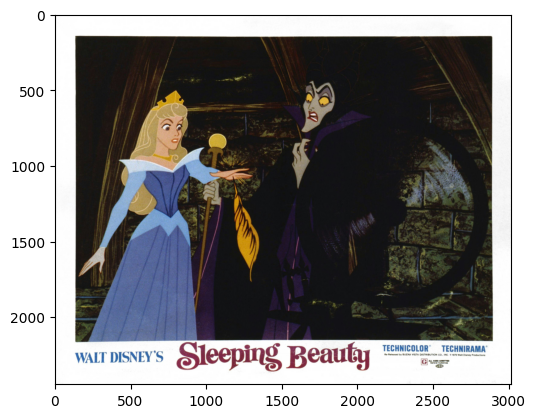

In [ ]:
path = "princess_guesser/src/aurora/test/aurora_1.jpg"
from matplotlib import pyplot as plt

plt.imshow(plt.imread(path))

Imports nécessaires

In [ ]:
import PIL
from PIL import Image
import csv
import numpy as np
import matplotlib.pyplot as plt
import os
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import models
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, Dropout, Input
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.optimizers import Adam


In [ ]:
def find_labels_from_pic(pic,src):
  for file in os.listdir(src):
    if file.endswith(".txt") and file[:-4]==pic[:-3]:
      #print(file)
      return file

In [ ]:
def find_pic_from_label(label,src):
  """Fonction qui prend le label d'une image en txt et renvoie le chemin de l'image"""
  for file in os.listdir(src):
    if file.startswith(label[:-4]) and not(file.endswith(".txt")):
      #print(file)
      return file

Création d'un fichier csv avec une ligne par label:
- Col 1 = train/test/val
- Col 2 = Aurora/Snow_white/Rapunzel , princess label
- Col 3 = full image path
- Col 4 = pic width
- Col 5 = pic height
- Col 6 = x_min
- Col 7 = y_min
- Col 8 = x_max
- Col 9 = y_max

In [ ]:
path_ims = "princess_guesser/src/"
csv_file = "princess_guesser/src/princess_guesser.csv"
with open(csv_file,'w') as csvfile:
  writer = csv.writer(csvfile, delimiter=',') # Removed quotechar='|'
  headers = ["Data","Princesse","image","width","height","x_min","y_min","x_max","y_max"]
  writer.writerow(headers)
  for princess in os.listdir(path_ims):
    if os.path.isdir(path_ims+princess):
      for folder in os.listdir(path_ims+princess):
        for label in os.listdir(path_ims+princess+"/"+folder):
          if label.endswith(".txt"):
            with open(path_ims+princess+"/"+folder+"/"+label) as f:
              lines = f.readlines()
              for line in lines:
                line = line.split(" ")
                princ = line[0]
                if princ=="0":
                  prince = "Aurora"
                elif princ=="1":
                  prince = "Snow_white"
                elif princ=="2":
                  prince = "Rapunzel"
                else:
                  print("cacccaaaaa")
                image = find_pic_from_label(label,path_ims+princess+"/"+folder)
                # print(image)
                im = Image.open(path_ims+princess+"/"+folder+"/"+image)
                width, height = im.size

                # Interpret YOLO format: center_x_norm, center_y_norm, width_norm, height_norm
                center_x_norm = float(line[1])
                center_y_norm = float(line[2])
                bbox_width_norm = float(line[3])
                bbox_height_norm = float(line[4].strip())

                # Convert normalized center-width-height to normalized min-max
                x_min_norm = center_x_norm - (bbox_width_norm / 2)
                y_min_norm = center_y_norm - (bbox_height_norm / 2)
                x_max_norm = center_x_norm + (bbox_width_norm / 2)
                y_max_norm = center_y_norm + (bbox_height_norm / 2)

                writer.writerow([folder,prince,princess+"/"+folder+"/"+image,width,height,x_min_norm,y_min_norm,x_max_norm,y_max_norm])

Trying to check the pictures with multiple labels to have an idea of how many and what folders or sub folders they are in

In [ ]:
###############################################################################################################################################################################
# Lecture du CSV contenant les informations relatives à la base de données
imgs_with_many_lab = []

# Correct file path and delimiter, remove quotechar
with open('princess_guesser/src/princess_guesser.csv', newline='') as csvfile:
	filereader = csv.reader(csvfile, delimiter=',')
	# Skip header
	header = next(filereader, None)
	for row in filereader:
		# Ensure the row has enough elements as per the defined headers
		if len(row) == 9:
			# Data,Princesse,image,width,height,x_min,y_min,x_max,y_max
			try:
				width = float(row[3])
				height = float(row[4])
				x_min = float(row[5])
				y_min = float(row[6])
				x_max = float(row[7])
				y_max = float(row[8])

				box = [x_min, y_min, x_max, y_max]
				new_entry = {
					'type': row[0], # 'Data' column (e.g., 'val', 'train')
					'princess': row[1], # 'Princesse' column
					'path': row[2], # 'image' path
					'shape': [width, height],
					'box': box
				}
				### append to imgs_with_many_lab if multiple labels same pic
				if row[2] in imgs_with_many_lab:
					imgs_with_many_lab.append(row[2])
				else:
					imgs_with_many_lab.append(row[2])
			except ValueError as e:
				print(f"Error parsing row: {row}. Details: {e}")


## Préparation des données
Le code ci-dessous permet de charger les données et les formater pour la classification.
Notez que les images sont rendues carrées lors du chargement.
Lecture du csv pour recup toutes les data

In [ ]:
# Lecture du CSV contenant les informations relatives à la base de données
dataset = []

# Correct file path and delimiter, remove quotechar
with open('princess_guesser/src/princess_guesser.csv', newline='') as csvfile:
	filereader = csv.reader(csvfile, delimiter=',')
	# Skip header
	header = next(filereader, None)
	for row in filereader:
		# Ensure the row has enough elements as per the defined headers
		if len(row) == 9:
			# Data,Princesse,image,width,height,x_min,y_min,x_max,y_max
			try:
				width = float(row[3])
				height = float(row[4])
				x_min = float(row[5])
				y_min = float(row[6])
				x_max = float(row[7])
				y_max = float(row[8])

				box = [x_min, y_min, x_max, y_max]
				new_entry = {
					'type': row[0], # 'Data' column (e.g., 'val', 'train')
					'princess': row[1], # 'Princesse' column
					'path': row[2], # 'image' path
					'shape': [width, height],
					'box': box
				}
				dataset.append(new_entry)
			except ValueError as e:
				print(f"Error parsing row: {row}. Details: {e}")
		else:
			print(f"Skipping malformed row (incorrect number of columns): {row}")

# Nombre de classes de la base de données et intitulé des classes
CLASS_LABELS = list(dict.fromkeys([item['princess'] for item in dataset]))
NB_CLASSES = len(CLASS_LABELS)

# Extraction des données d'apprentissage et de test
# Assuming 'train' and 'val' types based on typical splits and user's example
dataset_train = [item for item in dataset if item['type'].lower()=='train']
dataset_test = [item for item in dataset if (item['type'].lower()=='val' or item['type'].lower()=='test')]

print(CLASS_LABELS)
print(len(dataset_train))
print(len(dataset_test))
print(dataset_train[0])


['Rapunzel', 'Snow_white', 'Aurora']
491
204
{'type': 'train', 'princess': 'Rapunzel', 'path': 'rapunzel/train/kagglePrincess_1.png', 'shape': [119.0, 150.0], 'box': [0.5462184999999999, 0.1600005, 0.7226895, 0.3733335]}


In [ ]:
def build_localization_tensors(image_size, dataset, NB_CLASSES):
  # Préparation des structures de données pour x et y
  x = np.zeros((len(dataset), image_size, image_size, 3))
  y = np.empty((len(dataset), NB_CLASSES + 5)) # 1 + 4 + NB_CLASSES : présence / boîte englobante / classes

  # Compteur de parcours du dataset
  i = 0

  for item in dataset:
    # Lecture de l'image
    img = Image.open('princess_guesser/src/' + item['path'])
    # Convert image to RGB if it has an alpha channel
    if img.mode != 'RGB':
        img = img.convert('RGB')
    # Mise à l'échelle de l'image
    img = img.resize((image_size,image_size), Image.Resampling.LANCZOS)
    # Remplissage de la variable x
    x[i] = np.asarray(img)

    y[i, 0] = 1 # Un objet est toujours présent !

    # Coordonnées de boîte englobante
    # The box contains normalized x_min, y_min, x_max, y_max from the CSV
    box = item['box']

    # Convert normalized min-max to normalized center-width-height
    bx = (box[0] + box[2]) / 2  # (x_min_norm + x_max_norm) / 2
    by = (box[1] + box[3]) / 2  # (y_min_norm + y_max_norm) / 2
    bw = box[2] - box[0]        # x_max_norm - x_min_norm
    bh = box[3] - box[1]        # y_max_norm - y_min_norm

    y[i, 1] = bx
    y[i, 2] = by
    y[i, 3] = bw
    y[i, 4] = bh

    # Probabilités de classe, sous la forme d'une one-hot vector
    label = CLASS_LABELS.index(item['princess'])
    classes_probabilities = keras.utils.to_categorical(label, num_classes=NB_CLASSES)
    y[i, 5:] = classes_probabilities

    i = i+1

  return x, y

Séparation des données d'entraînement pour extraire un ensemble de validation, et pré-traitement des données.

In [ ]:
from sklearn.model_selection import train_test_split


# Pour la suite du TP on considèrera des images de taille 64x64x3
# Augmenter cette valeur donnerait de meilleurs résultats mais nécessiterait des calculs plus long.
IMAGE_SIZE = 64

# Lecture des données d'entraînement et de test
x, y = build_localization_tensors(IMAGE_SIZE, dataset_train, NB_CLASSES)
x_test, y_test = build_localization_tensors(IMAGE_SIZE, dataset_test, NB_CLASSES)

#Extraction d'un ensemble de validation
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=0.10, random_state=42)

# Pour améliorer l'entraînement, on peut centrer-réduire les coordonnées des bounding boxes...
y_std = np.std(y_train, axis=0)
y_mean = np.mean(y_train, axis=0)
y_train[...,1:5] = (y_train[...,1:5] - y_mean[1:5])/y_std[1:5]
y_val[...,1:5] = (y_val[...,1:5] - y_mean[1:5])/y_std[1:5]
y_test[...,1:5] = (y_test[...,1:5] - y_mean[1:5])/y_std[1:5]

# ... et normaliser les valeurs de couleur
x_train = x_train/255
x_val = x_val/255
x_test = x_test/255

## Fonctions utiles

Une fonction de calcul de l'intersection sur union, qui nous sera utile pour les métriques d'évaluation de nos méthodes :

$$ IoU (R_1, R_2) = \frac{\mathcal{A} (R_1 \cap R_2)}{\mathcal{A} (R_1 \cup R_2)} = \frac{\mathcal{A} (R_1 \cap R_2)}{\mathcal{A} (R_1) + \mathcal{A} (R_2) -  \mathcal{A} (R_1 \cap R_2)} $$

<center>
<img src="https://drive.google.com/thumbnail?id=1BQx2kDOCltZ_5gcnKVWTVUVNmGk-7qBC&sz=w1000" width=500>
</center>


In [ ]:
### A COMPLETER
def intersection_sur_union(box1, box2):
  """
  Calcul de l'intersection sur union entre deux rectangles box1 et box2

  Arguments:
  box1, box2 -- les coordonnées des deux rectangles, chacun sous la forme [cx, cy, w, h]
                où (cx, cy) désigne les coordonnées du centre du rectangle,
                w sa largeur et h sa hauteur

  Retourne :
  iou -- la valeur d'intersection sur union entre les deux rectangles
  """
  [cx1, cy1, w1, h1] = box1
  x1 = cx1 - w1/2
  y1 = cy1 - h1/2
  x2 = cx1 + w1/2
  y2 = cy1 + h1/2
  [cx2, cy2, w2, h2] = box2
  x3 = cx2 - w2/2
  y3 = cy2 - h2/2
  x4 = cx2 + w2/2
  y4 = cy2 + h2/2
  aire_inter = abs( max(x1,x3) - min(x2,x4)) * abs( max(y1,y3) - min(y2,y4))
  aire_r1 = abs(x2-x1) * abs(y2-y1)
  aire_r2 = abs(x4-x3) * abs(y4-y3)
  iou = aire_inter / (aire_r1 + aire_r2 - aire_inter)
  return iou

On va maintenant calculer les différentes métriques :

$$ P = \frac{TP}{TP + FP} $$

$$ R = \frac{TP}{TP + FN} $$

$$ F1 = \frac{2 * P * R}{P + R} $$

où $TP$ désigne le nombre de vrais positifs, $FP$ le nombre de faux positifs, $FN$ le nombre de faux négatifs, $P$ la précision, $R$ le rappel et $F1$ le F1-score.

On considère souvent qu'une détection est correcte si la classification est valide et que l'intersection sur union entre vérité terrain et prédiction est supérieure à 0.5 (on utilisera un seuil modifiable *iou_thres*).

In [ ]:
# On considère souvent qu'une détection est correcte si la classification est valide et que
# l'intersection sur union entre vérité terrain et prédiction est supérieure à 0.5
def global_accuracy(y_true, y_pred, iou_thres=0.5):
  """
  Calcul, pour chaque classe de la précision, du rappel et du F1-score ainsi
  que du pourcentage global de bonnes détections.

  Arguments:
  y_true -- les labels de la vérité terrain, de dimension (M, 1+4+N) où M désigne
          le nombre d'éléments du dataset et N le nombre de classes (11 dans notre cas)
  y_pred -- les labels prédits par un modèle, de dimension (M, 1+4+N)
  iou_thres -- seuil d'intersection sur union entre une boîte "vérité-terrain" et
              une boite prédite au-dessus duquel on considère que la prédiction est correcte

  Retourne :
  class_res -- liste de longueur N contenant des dictionnaires sous la forme
            {"Précision": p, "Rappel": r, "F-score": f} résumant les métriques
            précision, rappel et F1-score pour chacune des classes.
  accuracy -- pourcentage global de bonnes détections
  """
  # Initialisation des métriques : nombre de vrais positifs (TP), faux positifs (FP)
  # et faux négatifs (FN) pour chaque classe
  class_metrics = []
  NB_CLASSES_test = y_true.shape[0]
  for i in range(NB_CLASSES_test):
    class_metrics.append({'TP': 0, 'FP': 0, 'FN': 0})

  # Nombres de détections correctes et de détections incorrectes
  total_correct_detections = 0
  total_incorrect_detections = 0
  for i in range(y_true.shape[0]):
    # Labels vérité-terrain et prédits
    groundtruth_label = np.argmax(y_true[i,5:])
    predicted_label = np.argmax(y_pred[i,5:])

    # Coordonnées de boîtes englobantes réelles et prédites
    bx_true = (y_true[i,1]*y_std[1] + y_mean[1])
    by_true = (y_true[i,2]*y_std[2] + y_mean[2])
    bw_true = (y_true[i,3]*y_std[3] + y_mean[3])
    bh_true = (y_true[i,4]*y_std[4] + y_mean[4])
    bx_pred = (y_pred[i,1]*y_std[1] + y_mean[1])
    by_pred = (y_pred[i,2]*y_std[2] + y_mean[2])
    bw_pred = (y_pred[i,3]*y_std[3] + y_mean[3])
    bh_pred = (y_pred[i,4]*y_std[4] + y_mean[4])

    # Calcul de l'intersection sur union
    iou = intersection_sur_union([bx_true, by_true, bw_true, bh_true], [bx_pred, by_pred, bw_pred, bh_pred])

    ### A COMPLETER
    # Si la détection est correcte :
    if groundtruth_label == predicted_label and iou > iou_thres:
      # Mettre à jour le nombre de Vrais Positifs pour la classe vérité terrain :
      class_id = groundtruth_label
      class_metrics[class_id]['TP'] = class_metrics[class_id]['TP'] + 1
      total_correct_detections += 1
    else:
      # Mettre à jour le nombre de Faux Positifs et/ou Faux Négatifs pour les
      # classes concernées
      class_metrics[groundtruth_label]['FN'] = class_metrics[groundtruth_label]['FN'] + 1
      class_metrics[predicted_label]['FP'] = class_metrics[predicted_label]['FP'] + 1
      total_incorrect_detections += 1



  class_res = []
  for i in range(NB_CLASSES_test):
    # Pour chaque classe, on veut calculer Précision, Rappel et F1-Score à partir
    # des TP, FP et FN calculés sur le bloc précédent
    TP = class_metrics[i]['TP']
    FP = class_metrics[i]['FP']
    FN = class_metrics[i]['FN']
    if (TP + FP) == 0:
      P = 0
    else:
      P = TP / (TP + FP)

    if (TP + FN) == 0:
      R = 0
    else:
      R = TP / (TP + FN)

    if (P + R) == 0:
      F_score = 0
    else:
      F_score = (2 * P * R) / (P + R)
    class_res.append({'Precision': P, 'Rappel': R, 'F-score': F_score})

  # Pour calculer l'accuracy, il vous faut avoir mis à jour les variables
  # total_correct_detections et total_incorrect_detections
  accuracy = 100*total_correct_detections / (total_correct_detections + total_incorrect_detections)
  ### FIN
  return class_res, accuracy

La fonction ci-dessous permet de calculer l'intersection sur union  sur des tenseurs (et non des tableaux numpy), elle sera donc utilisable comme métrique pendant l'entraînement.

In [ ]:
def compute_iou(y_true, y_pred):
  ### "Dénormalisation" des coordonnées des boîtes englobantes
  pred_box_xy = y_pred[..., 0:2]* y_std[0:2] + y_mean[0:2]
  true_box_xy = y_true[..., 0:2]* y_std[0:2] + y_mean[0:2]

  ### "Dénormalisation" des largeur et hauteur des boîtes englobantes
  pred_box_wh = y_pred[..., 2:4] * y_std[2:4] + y_mean[2:4]
  true_box_wh = y_true[..., 2:4] * y_std[2:4] + y_mean[2:4]

  # Calcul des coordonnées minimales et maximales des boiptes englobantes réelles
  true_wh_half = true_box_wh / 2.
  true_mins    = true_box_xy - true_wh_half
  true_maxes   = true_box_xy + true_wh_half

  # Calcul des coordonnées minimales et maximales des boiptes englobantes prédites
  pred_wh_half = pred_box_wh / 2.
  pred_mins    = pred_box_xy - pred_wh_half
  pred_maxes   = pred_box_xy + pred_wh_half

  # Détermination de l'intersection des boîtes englobantes
  intersect_mins  = tf.maximum(pred_mins,  true_mins)
  intersect_maxes = tf.minimum(pred_maxes, true_maxes)
  intersect_wh    = tf.maximum(intersect_maxes - intersect_mins, 0.)
  intersect_areas = intersect_wh[..., 0] * intersect_wh[..., 1]

  # Aire des boîtes englobantes prédites et réelles
  true_areas = true_box_wh[..., 0] * true_box_wh[..., 1]
  pred_areas = pred_box_wh[..., 0] * pred_box_wh[..., 1]

  # Aire de l'union des boîtes prédites et réelles
  union_areas = pred_areas + true_areas - intersect_areas

  iou_scores  = tf.truediv(intersect_areas, union_areas)
  return iou_scores

def iou():
  def iou_metrics(y_true, y_pred):
    return compute_iou(y_true, y_pred)
  iou_metrics.__name__= "iou"
  return iou_metrics

Visualisation des données et labels

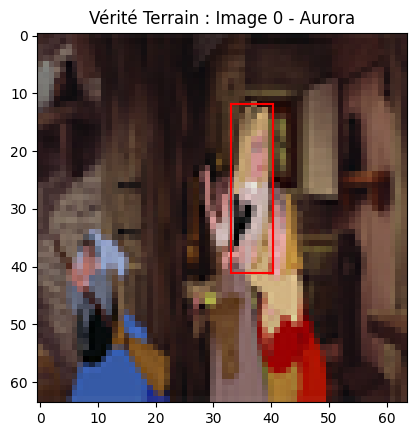

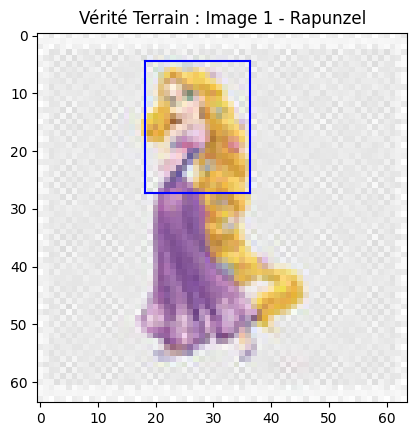

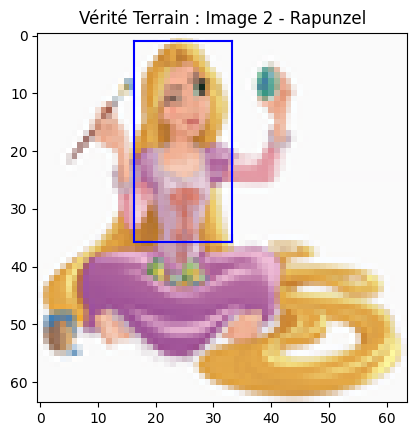

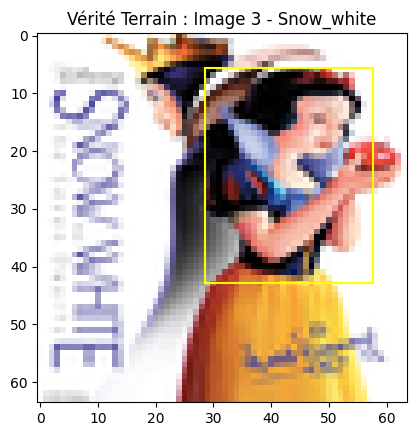

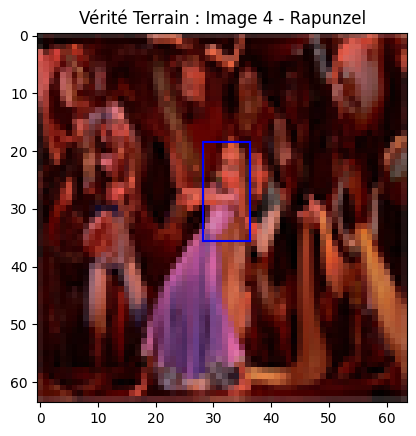

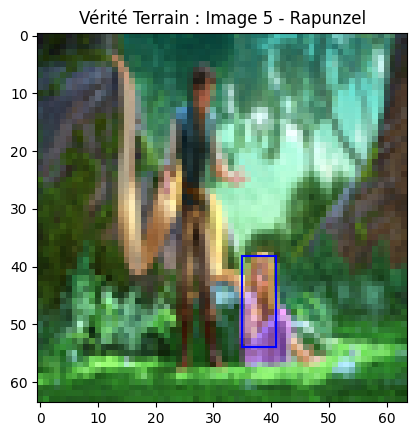

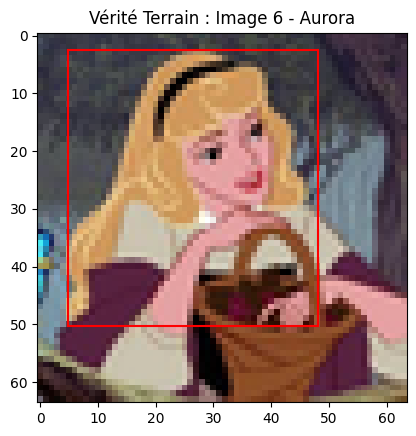

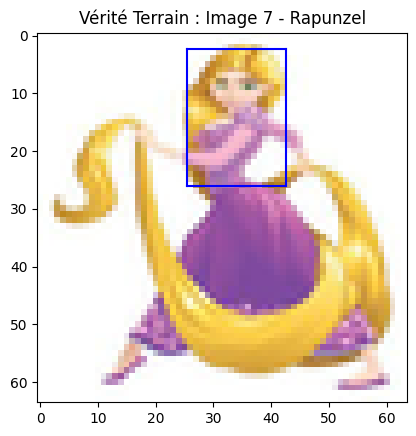

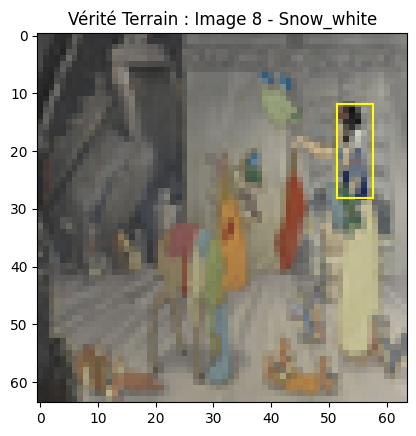

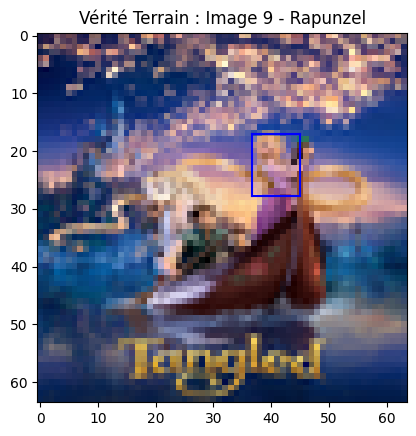

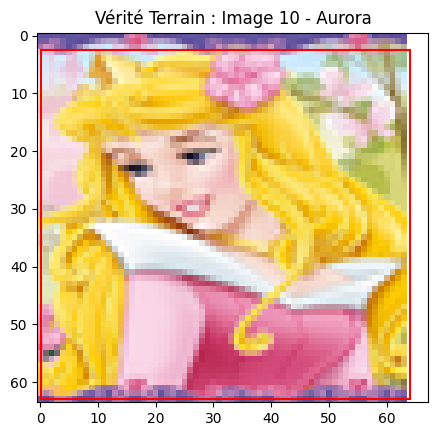

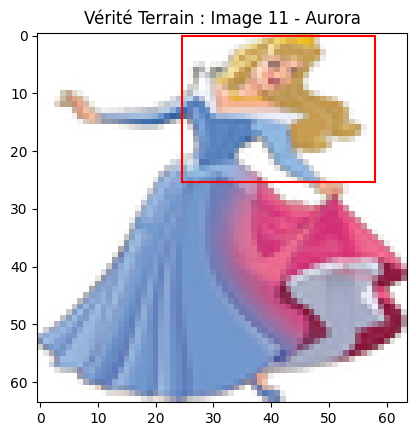

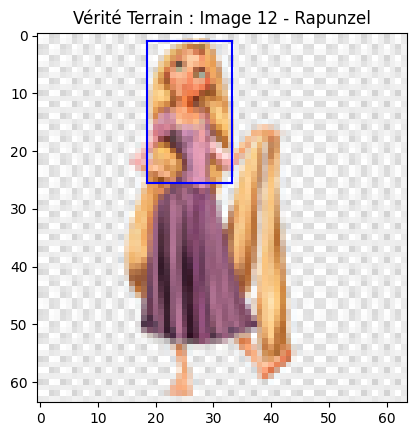

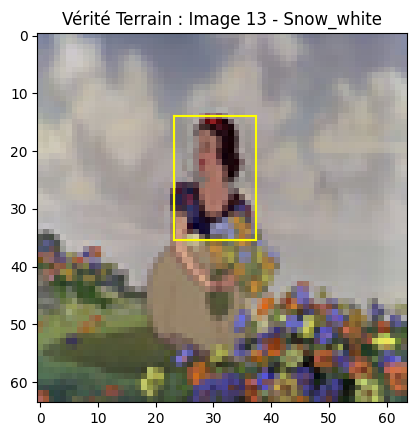

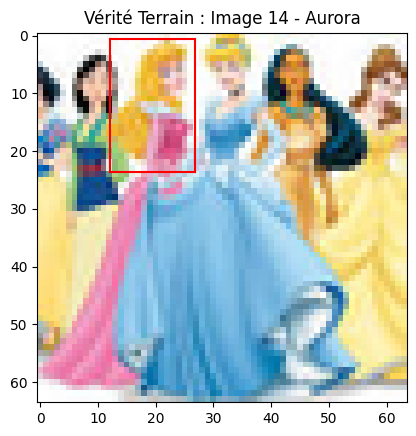

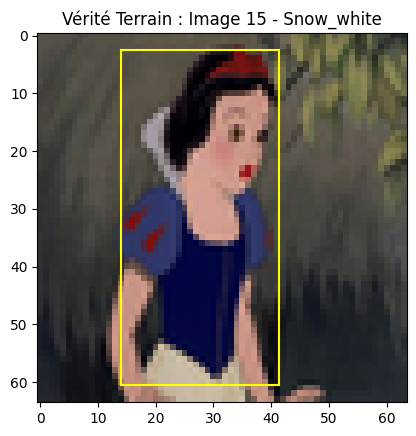

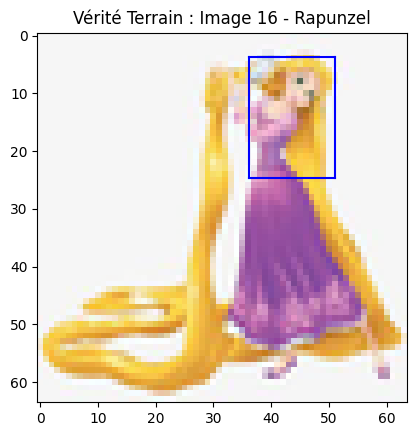

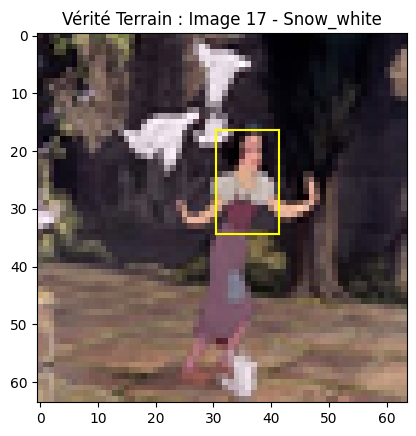

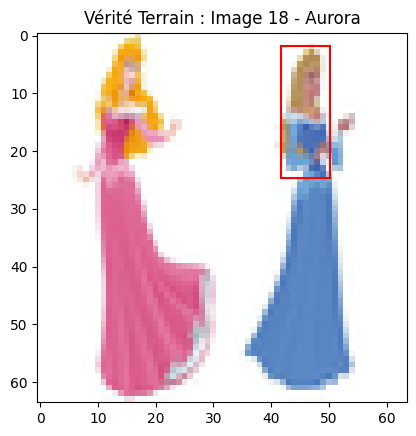

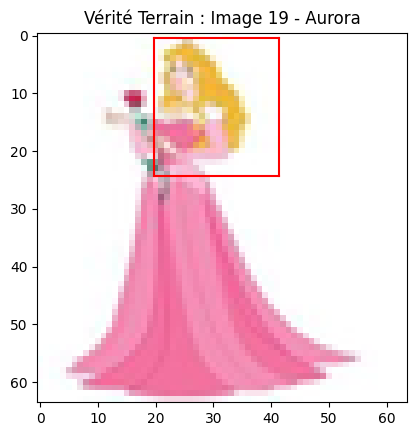

In [ ]:
# Si seuls x et y sont indiqués, on tire au hasard un numéro d'image et on affiche le label y associé  à l'image
# Si un 2e y, nommé y_pred, est indiqué, alors les deux labels sont affichés côte à côte, afin de pouvoir les comparer
# Enfin on peut également indiquer l'id de l'image que l'on souhaite visualiser.
def print_data_localisation(x, y, y_pred=[], id=None, image_size=64):
  if id==None:
    # Tirage aléatoire d'une image dans la base
    num_img = np.random.randint(x.shape[0]-1)
  else:
    num_img = id

  img = x[num_img]
  lab = y[num_img]

  colors = ["blue", "yellow", "red"] # Différentes couleurs pour les différentes classes
  classes = [ 'Rapunzel', 'Snow_white', 'Aurora']

  if np.any(y_pred):
    plt.subplot(1, 2, 1)

  # Affichage de l'image
  plt.imshow(img)
  # Détermination de la classe
  class_id = np.argmax(lab[5:])

  # Détermination des coordonnées de la boîte englobante dans le repère image
  ax = (lab[1]*y_std[1] + y_mean[1]) * image_size
  ay = (lab[2]*y_std[2] + y_mean[2]) * image_size
  width = (lab[3]*y_std[3] + y_mean[3]) * image_size
  height = (lab[4]*y_std[4] + y_mean[4]) * image_size
  #print("x: {}, y: {}, w: {}, h:{}".format(ax,ay,width, height))
  # Détermination des extrema de la boîte englobante
  p_x = [ax-width/2, ax+width/2]
  p_y = [ay-height/2, ay+height/2]
  # Affichage de la boîte englobante, dans la bonne couleur
  plt.plot([p_x[0], p_x[0]],p_y,color=colors[class_id])
  plt.plot([p_x[1], p_x[1]],p_y,color=colors[class_id])
  plt.plot(p_x,[p_y[0],p_y[0]],color=colors[class_id])
  plt.plot(p_x,[p_y[1],p_y[1]],color=colors[class_id])
  plt.title("Vérité Terrain : Image {} - {}".format(num_img, classes[class_id]))

  if np.any(y_pred):
    plt.subplot(1, 2, 2)
    # Affichage de l'image
    plt.imshow(img)
    lab = y_pred[num_img]
    # Détermination de la classe
    class_id = np.argmax(lab[5:])

    # Détermination des coordonnées de la boîte englobante dans le repère image
    ax = (lab[1]*y_std[1] + y_mean[1]) * image_size
    ay = (lab[2]*y_std[2] + y_mean[2]) * image_size
    width = (lab[3]*y_std[3] + y_mean[3]) * image_size
    height = (lab[4]*y_std[4] + y_mean[4]) * image_size
    #print("x: {}, y: {}, w: {}, h:{}".format(ax,ay,width, height))
    # Détermination des extrema de la boîte englobante
    p_x = [ax-width/2, ax+width/2]
    p_y = [ay-height/2, ay+height/2]
    # Affichage de la boîte englobante, dans la bonne couleur
    plt.plot([p_x[0], p_x[0]],p_y,color=colors[class_id])
    plt.plot([p_x[1], p_x[1]],p_y,color=colors[class_id])
    plt.plot(p_x,[p_y[0],p_y[0]],color=colors[class_id])
    plt.plot(p_x,[p_y[1],p_y[1]],color=colors[class_id])
    plt.title("Prédiction : Image {} - {}".format(num_img, classes[class_id]))

  plt.show()

for i in range(20):#x.shape[0]):
    print_data_localisation(x_train, y_train, image_size=IMAGE_SIZE, id=i)


Let's examine image 6 more closely to understand why the label might be off.

Raw y_train data for image 6: [ 1.         -0.52962572  0.09982961  2.0256418   1.06834801  0.
  0.          1.        ]
Image path: rapunzel/train/rapunzel_8.jpg


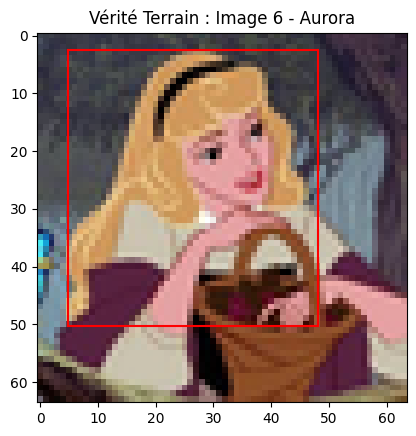

In [ ]:
print(f"Raw y_train data for image 6: {y_train[6]}")
#print data path
print(f"Image path: {dataset_train[6]['path']}")
print_data_localisation(x_train, y_train, image_size=IMAGE_SIZE, id=6)

In [ ]:
def plot_training_analysis(history, metric='loss'):

  loss = history.history[metric]
  val_loss = history.history['val_' + metric]

  epochs = range(len(loss))

  plt.plot(epochs, loss, 'b', linestyle="--",label='Training ' + metric)
  plt.plot(epochs, val_loss, 'g', label='Validation ' + metric)
  plt.title('Training and validation ' + metric)
  plt.legend()

  plt.show()

## Travail à faire

<center> <img src="https://drive.google.com/thumbnail?id=1YzCZe4pgnjJDVGklAaCHZ7HhlPJsadg9&sz=w1000" width=500></center>
<caption><center> Figure 3: Illustration de l'architecture du réseau à construire.  </center></caption>

Complétez les codes qui vous sont fournis pour obtenir un algorithme de localisation.
Vous pouvez utiliser n'importe quelle base convolutive de votre choix (vous pouvez vous inspirer du TP sur les CNN que nous avons fait l'an passé), en revanche vous devrez porter une attention particulière à la couche de sortie.

Vous allez en fait produire 3 sorties différentes : une caractérisant la présence d'un objet, une autre fournissant les coordonnées de la boîte englobante, et enfin une dernière effectuant la classification.

In [ ]:
def create_model_localisation(input_shape=(64, 64, 3)):

  input_layer = Input(shape=input_shape)

  conv1 = Conv2D(32, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(input_layer)
  conv1 = Conv2D(32, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv1)
  pool1 = MaxPooling2D(pool_size=(2, 2))(conv1)
  ### A COMPLETER
  conv2 = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(pool1)
  conv2 = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = 'he_normal')(conv2)
  pool2 = MaxPooling2D(pool_size=(2, 2))(conv2)

  conv3 = Conv2D(128, 3, activation='relu', padding = 'same', kernel_initializer = 'he_normal')(pool2)
  conv3 = Conv2D(128, 3, activation='relu', padding = 'same', kernel_initializer = 'he_normal')(conv3)
  pool3 = MaxPooling2D(pool_size=(2, 2))(conv3)

  conv4 = Conv2D(256, 3, activation='relu', padding = 'same', kernel_initializer = 'he_normal')(pool3)
  conv4 = Conv2D(256, 3, activation='relu', padding = 'same', kernel_initializer = 'he_normal')(conv4)
  drop4 = Dropout(0.5)(conv4)
  pool4 = MaxPooling2D(pool_size=(2, 2))(drop4)

  # Cette couche vectorise le tenseur de sortie de votre base convolutive, et
  # constituera l'entrée des 3 couches de sortie ci-dessous
  prev_layer = Flatten()(pool4)

  #### Couches de sortie A COMPLETER
  output_p = Dense(1, activation='sigmoid', name='p')(prev_layer)   # Sortie caractérisant la présence d'un objet
  output_coord = Dense(4, activation='linear', name='coord')(prev_layer) # Sortie caractérisant les coordonnées de boîte englobante
  output_class = Dense(NB_CLASSES, activation='softmax', name='classes')(prev_layer) # Sortie caractérisant les probabilités de classe

  output= [output_p, output_coord, output_class]
  model = Model(input_layer, output)

  return model




Pour entraîner votre réseau, vous allez donc devoir associer une fonction de coût à chacune des sorties du réseau. La fonction de coût totale sera la somme des trois fonctions de coût précédemment définies, pondérées par des poids définis dans la variable *loss_weights*.

**Prenez le temps de tester différentes valeurs de *loss_weights* en fonction de l'évolution des métriques que vous observerez pendant l'entraînement.**

Vous évaluerez vos résultats de manière qualitative (en affichant les boîtes englobantes prédites et réelles) mais aussi quantitatives grâce aux fonctions définies dans la section précédente. **N'hésitez pas à modifier un peu le paramètre iou_threshold positionné par défaut à 0.5** (une valeur de 0.4 vous permettra d'obtenir de meilleurs résultats !)

In [ ]:
batch_size=16
model = create_model_localisation()
opt = Adam(learning_rate=3e-4)

# Ici mettre, dans l'ordre, les fonctions de coût associées à chacune des sorties
loss=[keras.losses.BinaryCrossentropy, keras.losses.MeanSquaredError, keras.losses.BinaryCrossentropy]
# On va associer une métrique à chaque sortie : l'accuracy pour les deux classifications,
# et l'IoU définie plus tôt pour la qualité des boîtes englobantes.
metrics=[ ['accuracy'], [iou()], ['accuracy']]
loss_weights = [1, 1, 1]

model.compile(loss=loss,
              optimizer=opt,
              metrics=metrics,
              loss_weights=loss_weights
              )
history = model.fit(x_train, [y_train[:,0], y_train[:,1:5], y_train[:,5:]],
              epochs=50,
              batch_size=batch_size,
              validation_data=(x_val, [y_val[:,0], y_val[:,1:5], y_val[:,5:]]))


Epoch 1/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 21s 596ms/step - classes_accuracy: 0.3333 - classes_loss: 0.6636 - coord_iou: 0.2693 - coord_loss: 1.7578 - loss: 2.5282 - p_accuracy: 0.9637 - p_loss: 0.0924 - val_classes_accuracy: 0.4000 - val_classes_loss: 0.6366 - val_coord_iou: 0.3475 - val_coord_loss: 1.0110 - val_loss: 1.8542 - val_p_accuracy: 1.0000 - val_p_loss: 0.0655
Epoch 2/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 22s 634ms/step - classes_accuracy: 0.4263 - classes_loss: 0.6182 - coord_iou: 0.3467 - coord_loss: 0.9025 - loss: 1.5335 - p_accuracy: 1.0000 - p_loss: 0.0099 - val_classes_accuracy: 0.4000 - val_classes_loss: 0.6307 - val_coord_iou: 0.3776 - val_coord_loss: 0.9432 - val_loss: 1.7833 - val_p_accuracy: 1.0000 - val_p_loss: 0.0305
Epoch 3/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 19s 577ms/step - classes_accuracy: 0.4921 - classes_loss: 0.5886 - coord_iou: 0.3643 - coord_loss: 0.8426 - loss: 1.4299 - p_accuracy: 1.0000 - p_loss: 0.0051 - val_classes_accuracy: 0.3600 - val_classes_loss: 0.6248 - val_c

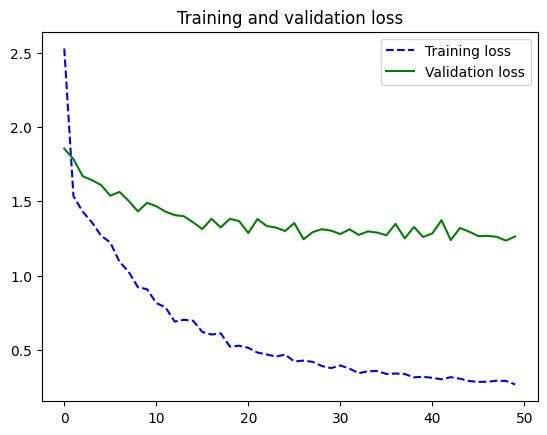

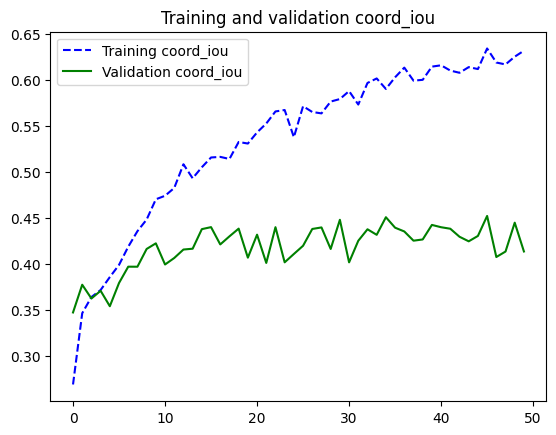

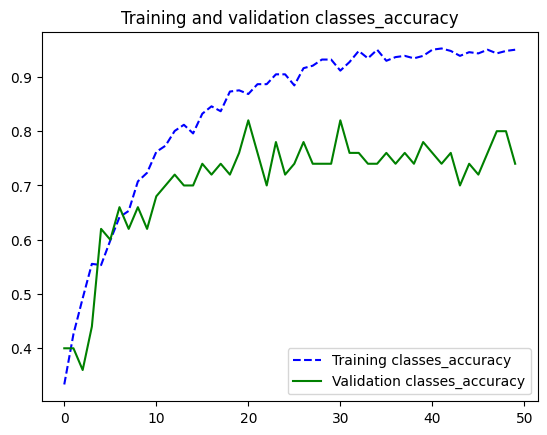

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 258ms/step


/tmp/ipykernel_16021/1470267387.py:10: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_pred[i, 0] = y_pred_presence[i]


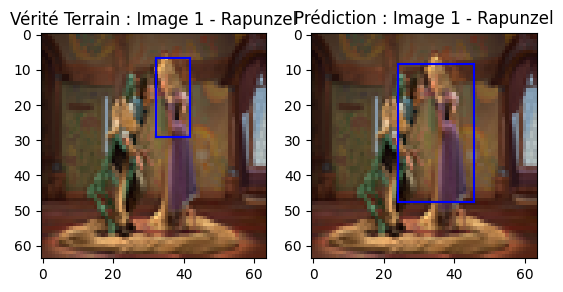

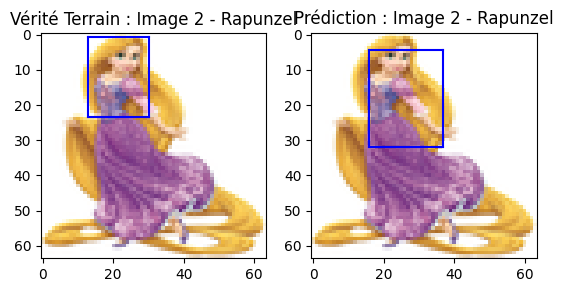

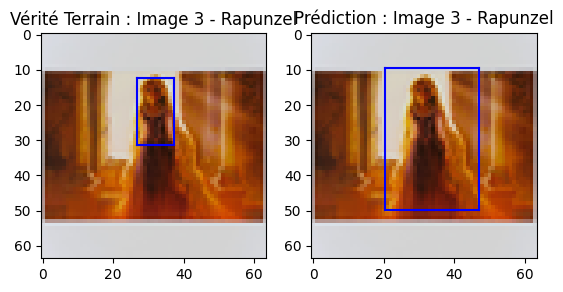

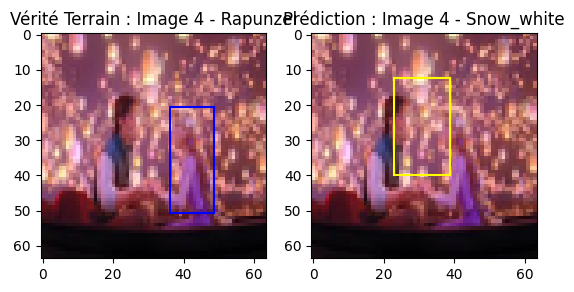

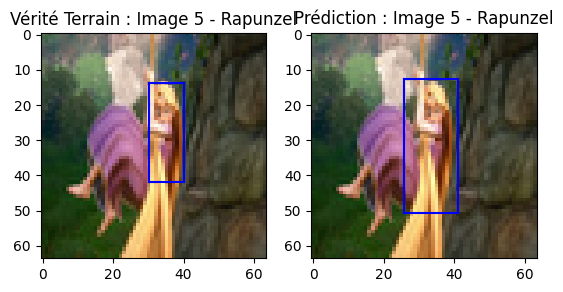

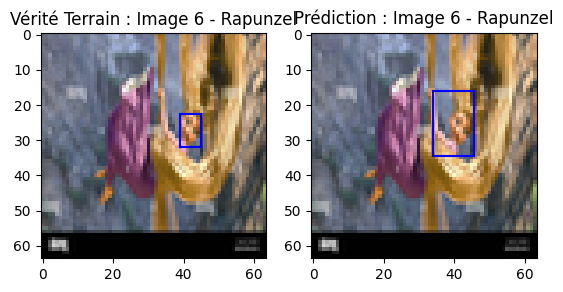

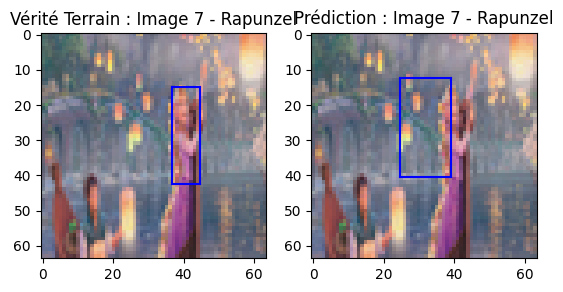

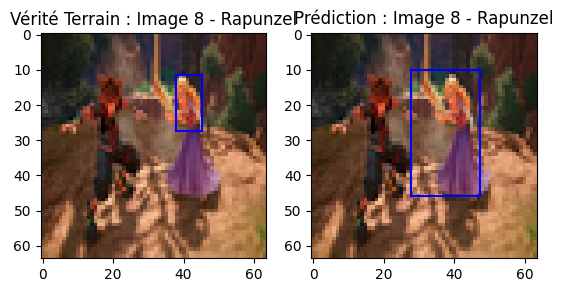

In [ ]:
# Analyse des résultats : courbes d'évolution de la fonction de perte, et de l'IoU des boîtes englobantes ainsi que de la précision des classes prédites
plot_training_analysis(history, metric='loss')
plot_training_analysis(history, metric='coord_iou')
plot_training_analysis(history, metric='classes_accuracy')

# Prédiction des données de test
y_pred_presence, y_pred_coords, y_pred_classes = model.predict(x_test)
y_pred = np.zeros(y_test.shape)
for i in range(y_pred.shape[0]):
  y_pred[i, 0] = y_pred_presence[i]
  y_pred[i, 1:5] = y_pred_coords[i]
  y_pred[i, 5:] = y_pred_classes[i]

# Affichage des résultats sur plusieurs images
print_data_localisation(x_test, y_test, y_pred = y_pred, id=1, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=2, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=3, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=4, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=5, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=6, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=7, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=8, image_size=IMAGE_SIZE)

In [ ]:
class_res, accuracy = global_accuracy(y_test, y_pred)

print(f"La précision globale est de {accuracy:.1f}%")

print()
print("------------------------------------------")
print("| Classe | Précision | Rappel | F1-score |")
print("------------------------------------------")
for i in range(NB_CLASSES):
  print(f"| {CLASS_LABELS[i]:7s}|   {class_res[i]['Precision']:.2f}    |  {class_res[i]['Rappel']:.2f}  |   {class_res[i]['F-score']:.2f}   |")
  print("------------------------------------------")


La précision globale est de 26.0%

------------------------------------------
| Classe | Précision | Rappel | F1-score |
------------------------------------------
| Rapunzel|   0.14    |  0.18  |   0.16   |
------------------------------------------
| Snow_white|   0.36    |  0.38  |   0.36   |
------------------------------------------
| Aurora |   0.33    |  0.22  |   0.26   |
------------------------------------------


En pratique, il est délicat de trouver une bonne combinaison des fonctions de perte tel que vous l'avez fait sur les cellules précédentes. L'entropie croisée et l'erreur quadratique moyenne donnent des valeurs trop différentes pour être combinables efficacement.

Une variante, peut-être plus simple à faire fonctionner, est d'utiliser uniquement l'erreur quadratique moyenne comme perte pour toutes les sorties. C'est cette variante qui est implémentée dans l'algorithme YOLO, dont nous implémenterons une version simplifiée dans la suite du TP.
Testez cette solution ci-dessous. Comme sur l'exercice précédent, n'hésitez pas à faire varier le poids des différents éléments de la fonction de coût.

In [ ]:
##################################### mean square error ######################################################
batch_size=16
model = create_model_localisation()
opt = Adam(learning_rate=3e-4)

loss = [keras.losses.MeanSquaredError, keras.losses.MeanSquaredError, keras.losses.MeanSquaredError]
metrics =[ ['accuracy'], [iou()], ['accuracy']]
loss_weights = [1, 1, 1]

model.compile(loss=loss,
              optimizer=opt,
              metrics=metrics,
              loss_weights=loss_weights
              )
history = model.fit(x_train, [y_train[:,0], y_train[:,1:5], y_train[:,5:]],
              epochs=50,
              batch_size=batch_size,
              validation_data=(x_val, [y_val[:,0], y_val[:,1:5], y_val[:,5:]]))


Epoch 1/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 21s 623ms/step - classes_accuracy: 0.3197 - classes_loss: 0.2445 - coord_iou: 0.2631 - coord_loss: 2.6991 - loss: 3.0007 - p_accuracy: 0.9864 - p_loss: 0.0258 - val_classes_accuracy: 0.2800 - val_classes_loss: 0.2324 - val_coord_iou: 0.3553 - val_coord_loss: 0.9995 - val_loss: 1.4320 - val_p_accuracy: 1.0000 - val_p_loss: 0.0318
Epoch 2/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 19s 573ms/step - classes_accuracy: 0.4308 - classes_loss: 0.2147 - coord_iou: 0.3309 - coord_loss: 0.9475 - loss: 1.1580 - p_accuracy: 1.0000 - p_loss: 0.0064 - val_classes_accuracy: 0.4000 - val_classes_loss: 0.2089 - val_coord_iou: 0.3132 - val_coord_loss: 1.0313 - val_loss: 1.3808 - val_p_accuracy: 1.0000 - val_p_loss: 0.0127
Epoch 3/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 21s 608ms/step - classes_accuracy: 0.4875 - classes_loss: 0.2007 - coord_iou: 0.3480 - coord_loss: 0.8861 - loss: 1.0916 - p_accuracy: 1.0000 - p_loss: 0.0021 - val_classes_accuracy: 0.4400 - val_classes_loss: 0.2049 - val_c

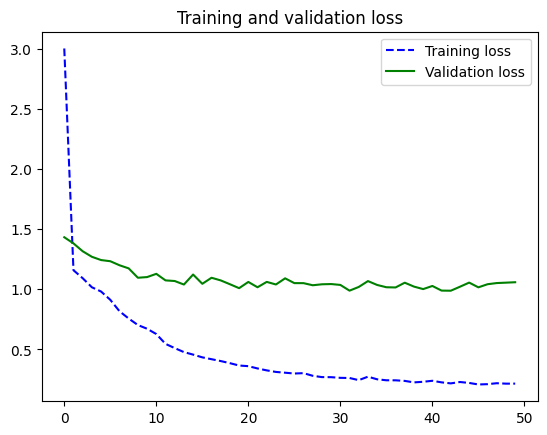

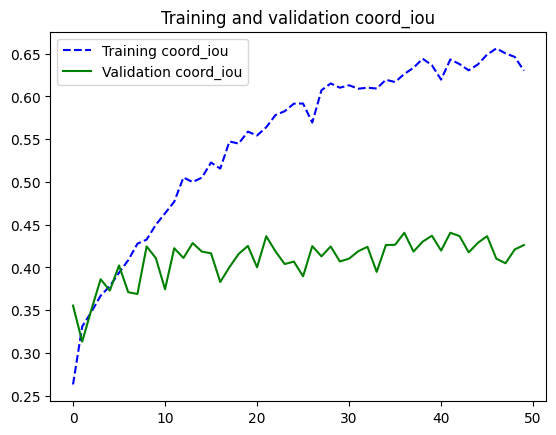

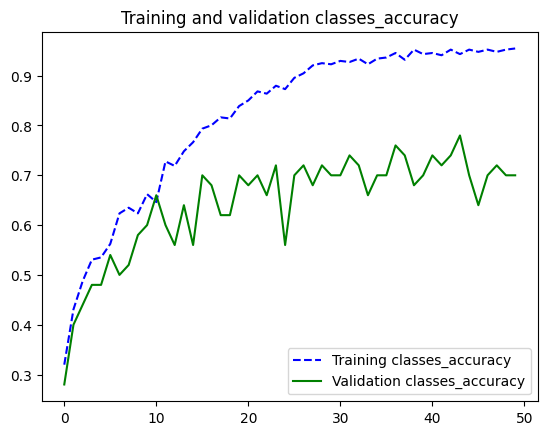

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 289ms/step


/tmp/ipykernel_16021/503295448.py:10: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_pred[i, 0] = y_pred_presence[i]


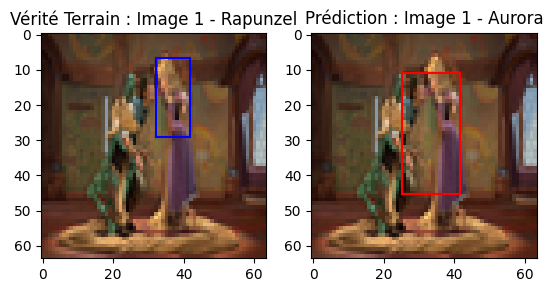

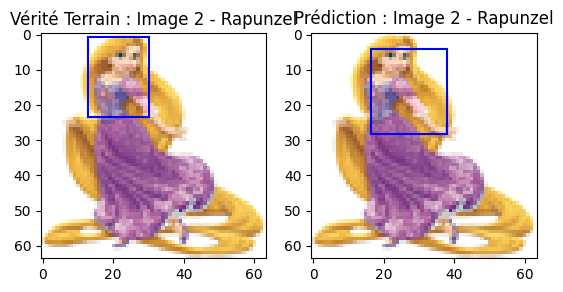

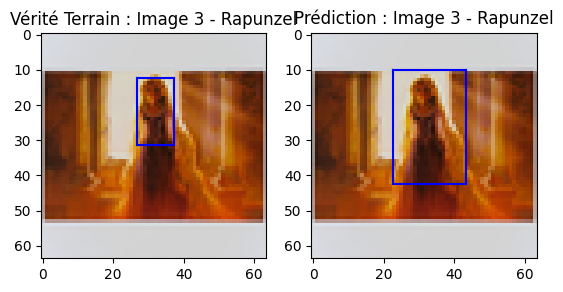

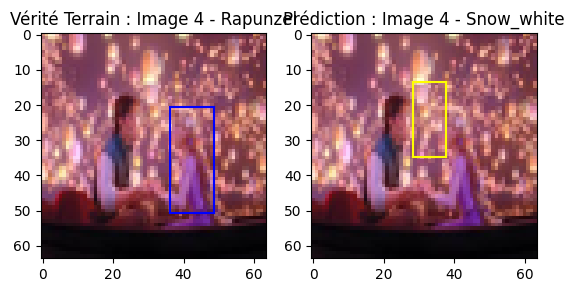

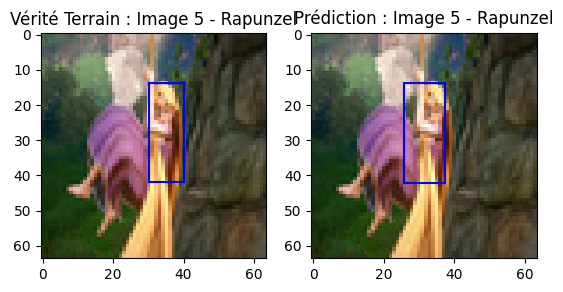

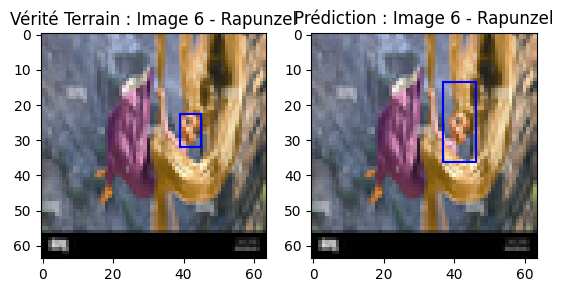

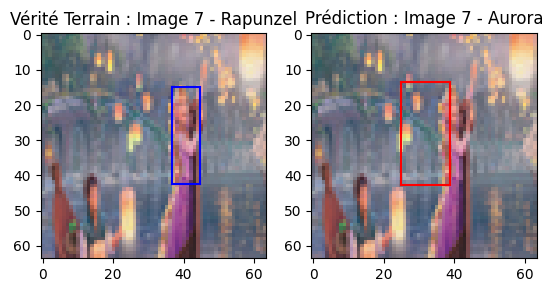

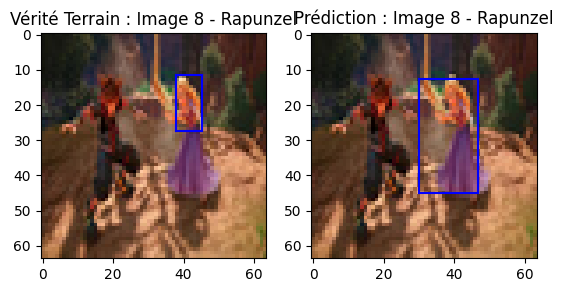

La précision globale est de 35.8%

------------------------------------------
| Classe | Précision | Rappel | F1-score |
------------------------------------------
| Rapunzel|   0.27    |  0.21  |   0.24   |
------------------------------------------
| Snow_white|   0.41    |  0.49  |   0.44   |
------------------------------------------
| Aurora |   0.36    |  0.37  |   0.37   |
------------------------------------------


In [ ]:
# Analyse des résultats : courbes d'évolution de la fonction de perte, et de l'IoU des boîtes englobantes ainsi que de la précision des classes prédites
plot_training_analysis(history, metric='loss')
plot_training_analysis(history, metric='coord_iou')
plot_training_analysis(history, metric='classes_accuracy')

# Prédiction des données de test
y_pred_presence, y_pred_coords, y_pred_classes = model.predict(x_test)
y_pred = np.zeros(y_test.shape)
for i in range(y_pred.shape[0]):
  y_pred[i, 0] = y_pred_presence[i]
  y_pred[i, 1:5] = y_pred_coords[i]
  y_pred[i, 5:] = y_pred_classes[i]

# Affichage des résultats sur plusieurs images
print_data_localisation(x_test, y_test, y_pred = y_pred, id=1, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=2, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=3, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=4, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=5, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=6, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=7, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=8, image_size=IMAGE_SIZE)


class_res, accuracy = global_accuracy(y_test, y_pred, iou_thres=0.4)

print(f"La précision globale est de {accuracy:.1f}%")

print()
print("------------------------------------------")
print("| Classe | Précision | Rappel | F1-score |")
print("------------------------------------------")
for i in range(NB_CLASSES):
  print(f"| {CLASS_LABELS[i]:7s}|   {class_res[i]['Precision']:.2f}    |  {class_res[i]['Rappel']:.2f}  |   {class_res[i]['F-score']:.2f}   |")
  print("------------------------------------------")


Compte-tenu de la taille réduite de la base de données, les résultats ne sont pas mal du tout ! On observe quelques confusions entre certaines classes mais les prédictions sont souvent intéressantes.


Il devrait cependant subsister un fort surapprentissage à ce stade. Comme nous l'avons vu en première année, vous avez plusieurs possibilités qui s'offrent à vous pour le corriger :

*   Augmentation de la base de données. Vous pouvez pour cela vous appuyer sur le code fourni ci-dessous, avec une classe *Sequence* et l'utilisation de la librairie *Albumentation*.
*   Utilisation de *transfer learning* : partant d'un réseau entraîné sur ImageNet (qui contient de nombreuses classes d'animaux), vous bénéficieriez de filtres très généraux qui aiderait à limiter le surapprentissage.

Le bloc de code suivant permet de définir des transformations colorimétriques à appliquer à notre base de données, de manière à augmenter artificiellement le nombre d'images de celles-ci :

In [ ]:
############################################# DATA AUGMMMMM ##############################################################################
from albumentations import (Compose, RandomBrightnessContrast, RandomGamma, ShiftScaleRotate, RandomSizedBBoxSafeCrop)
import albumentations as A

AUGMENTATIONS_TRAIN = Compose([
    RandomGamma(gamma_limit=(80, 120), p=0.5),
    RandomBrightnessContrast(brightness_limit=(-0.2, 0.2), contrast_limit=(-0.2, 0.2), p=0.5)
], bbox_params=A.BboxParams(format='yolo', label_fields=['labels']))

/usr/local/lib/python3.12/dist-packages/albumentations/core/composition.py:331: UserWarning: Got processor for bboxes, but no transform to process it.
  self._set_keys()


En première année, nous avons implémenté l'augmentation de données à l'aide d'un objet ImageDataGenerator. La limite de cette méthode est qu'elle ne peut s'appliquer que dans des cas où l'augmentation de données ne modifie pas le label associé à l'image. C'était le cas dans le TP de l'an passé sur les chiens et les chats : appliquer une rotation ou une translation à une image de chien (ou de chat) ne changeait rien au fait que l'image montrait un chien (ou un chat).

Ici, il peut arriver que certaines transformations altèrent le label : une rotation appliquée à un objet en changera nécessairement les coordonnées de boîte englobante.
Pour gérer cette difficulté, on va implémenter nous même le chargement des données, à l'aide d'un objet ```Sequence``` (défini ci-dessous).

La méthode ```__get_item()__``` récupère les données et labels du prochain batch à fournir au modèle pour la descente de gradient. On peut ainsi, à la volée, appliquer l'augmentation de données sur les images et impacter la modification sur les labels associés (fonction ```apply_augmentation```).

In [ ]:
from tensorflow.keras.utils import Sequence

class PrincesseSequence(Sequence):
    # Initialisation de la séquence avec différents paramètres
    def __init__(self, x_set, y_set, batch_size,augmentations):
        self.x, self.y = x_set, y_set
        self.classes = ['Snow_white', 'Aurora', 'Rapunzel']
        self.batch_size = batch_size
        self.augment = augmentations
        self.indices1 = np.arange(x_set.shape[0])
        np.random.shuffle(self.indices1) # Les indices permettent d'accéder
        # aux données et sont randomisés à chaque epoch pour varier la composition
        # des batches au cours de l'entraînement

    # Fonction calculant le nombre de pas de descente du gradient par epoch
    def __len__(self):
        return int(np.ceil(len(self.x) / float(self.batch_size)))

    # Il y a des problèmes d'arrondi dans les conversions de boîtes englobantes
    # internes à la librairie Albumentations
    # Pour les contourner, si les boîtes sont trop proches des bords, on les érode un peu
    def erode_bounding_box(self, box):
        epsilon = 0.01

        xmin = max(box[0] - box[2]/2, epsilon)
        ymin = max(box[1] - box[3]/2, epsilon)
        xmax = min(box[0] + box[2]/2, 1-epsilon)
        ymax = min(box[1] + box[3]/2, 1-epsilon)

        cx = xmin + (xmax - xmin)/2
        cy = ymin + (ymax - ymin)/2
        width = xmax - xmin
        height = ymax - ymin

        return np.array([cx, cy, width, height])

    # Application de l'augmentation de données à chaque image du batch et aux
    # boîtes englobantes associées
    def apply_augmentation(self, bx, by):

        batch_x = np.zeros((bx.shape[0], IMAGE_SIZE, IMAGE_SIZE, 3))
        batch_y = by

        # Pour chaque image du batch
        for i in range(len(bx)):
            bboxes = []
            box = by[i,1:5]
            # Dénormalisation des coordonnées de boites englobantes
            box[0] = (box[0]*y_std[1] + y_mean[1])
            box[1] = (box[1]*y_std[2] + y_mean[2])
            box[2] = (box[2]*y_std[3] + y_mean[3])
            box[3] = (box[3]*y_std[4] + y_mean[4])
            box = self.erode_bounding_box(box)
            bboxes.append(box)

            class_labels = []
            class_id = np.argmax(by[i, 5:])
            class_labels.append(self.classes[class_id])

            img = bx[i]

            # Application de l'augmentation à l'image et aux masques
            transformed = self.augment(image=img.astype('float32'), bboxes=bboxes, labels=class_labels)
            batch_x[i] = transformed['image']
            batch_y_transformed = transformed['bboxes']

            # Renormalisation des coordonnées de boîte englobante transformée
            batch_y[i, 1] = (batch_y_transformed[0][0] - y_mean[1])/y_std[1]
            batch_y[i, 2] = (batch_y_transformed[0][1] - y_mean[2])/y_std[2]
            batch_y[i, 3] = (batch_y_transformed[0][2] - y_mean[3])/y_std[3]
            batch_y[i, 4] = (batch_y_transformed[0][3] - y_mean[4])/y_std[4]

        return batch_x, batch_y

    # Fonction appelée à chaque nouveau batch : sélection et augmentation des données
    def __getitem__(self, idx):
        batch_x = self.x[self.indices1[idx * self.batch_size:(idx + 1) * self.batch_size]]
        batch_y = self.y[self.indices1[idx * self.batch_size:(idx + 1) * self.batch_size]]
        batch_x, batch_y = self.apply_augmentation(batch_x, batch_y)

        batch_y = np.array(batch_y)
        return np.array(batch_x), (batch_y[:,0], batch_y[:,1:5].astype('float32'), batch_y[:,5:])

    # Fonction appelée à la fin d'un epoch ; on randomise les indices d'accès aux données
    def on_epoch_end(self):
        np.random.shuffle(self.indices1)



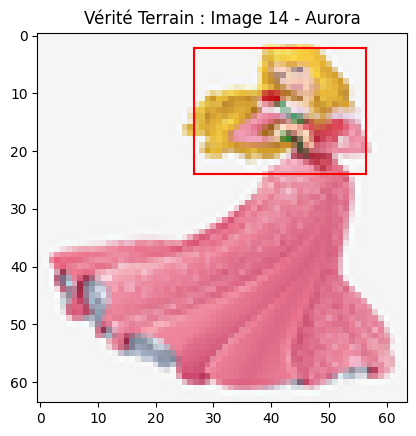

In [ ]:
# Instanciation d'une Sequence
train_gen = PrincesseSequence(x_train, y_train, 16, augmentations=AUGMENTATIONS_TRAIN)

# Pour tester la séquence, nous sélectionnons les éléments du premier batch et les affichons
batch_x, batch_y = train_gen.__getitem__(0)

y_batch = np.zeros((batch_y[0].shape[0],1+4+NB_CLASSES))

for i in range(batch_y[0].shape[0]):
  y_batch[i, 0] = batch_y[0][i]
  y_batch[i, 1:5] = batch_y[1][i]
  y_batch[i, 5:] = batch_y[2][i]

print_data_localisation(batch_x, y_batch, image_size=IMAGE_SIZE)

In [ ]:
batch_size=16
model = create_model_localisation()
opt = Adam(learning_rate=3e-4)

loss = [keras.losses.MeanSquaredError, keras.losses.MeanSquaredError, keras.losses.MeanSquaredError]
metrics =[ ['accuracy'], [iou()], ['accuracy']]
loss_weights = [1, 1, 1]

model.compile(loss=loss,
              optimizer=opt,
              metrics=metrics,
              loss_weights=loss_weights
              )
history = model.fit(train_gen,
              epochs=50,
              batch_size=batch_size,
              validation_data=(x_val, [y_val[:,0], y_val[:,1:5], y_val[:,5:]]))


Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


28/28 ━━━━━━━━━━━━━━━━━━━━ 22s 637ms/step - classes_accuracy: 0.3764 - classes_loss: 0.2342 - coord_iou: 0.2433 - coord_loss: 2.4378 - loss: 2.7529 - p_accuracy: 0.9524 - p_loss: 0.0508 - val_classes_accuracy: 0.3000 - val_classes_loss: 0.2237 - val_coord_iou: 0.3038 - val_coord_loss: 1.0556 - val_loss: 1.4424 - val_p_accuracy: 1.0000 - val_p_loss: 0.0323
Epoch 2/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 19s 583ms/step - classes_accuracy: 0.4127 - classes_loss: 0.2159 - coord_iou: 0.3347 - coord_loss: 0.9102 - loss: 1.1302 - p_accuracy: 1.0000 - p_loss: 0.0061 - val_classes_accuracy: 0.3800 - val_classes_loss: 0.2193 - val_coord_iou: 0.3401 - val_coord_loss: 0.9592 - val_loss: 1.3732 - val_p_accuracy: 1.0000 - val_p_loss: 0.0085
Epoch 3/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 594ms/step - classes_accuracy: 0.5102 - classes_loss: 0.2007 - coord_iou: 0.3584 - coord_loss: 0.8257 - loss: 1.0339 - p_accuracy: 1.0000 - p_loss: 0.0014 - val_classes_accuracy: 0.4800 - val_classes_loss: 0.2024 - val_coord_iou: 0

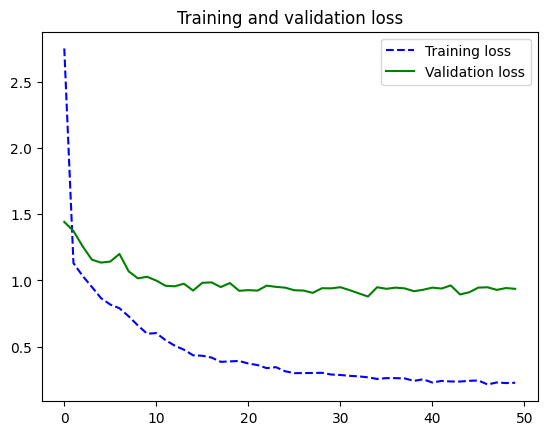

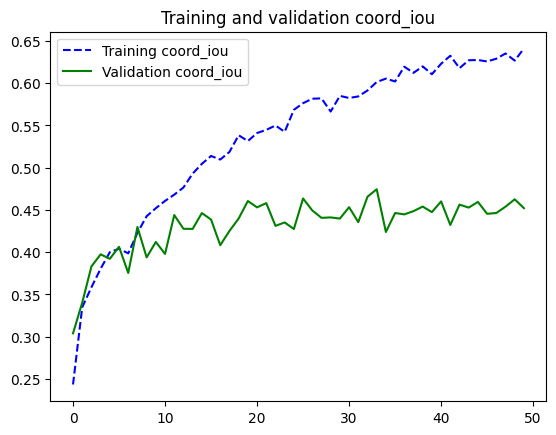

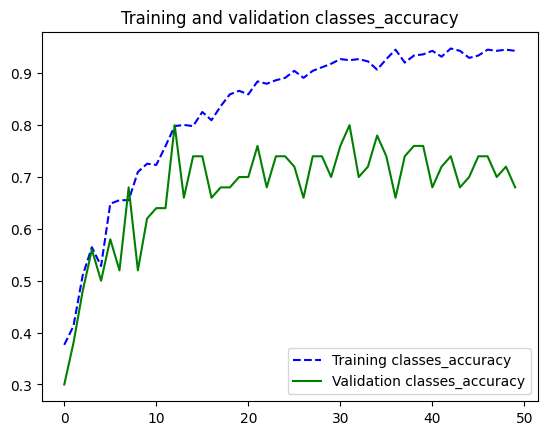

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 260ms/step


/tmp/ipykernel_16021/503295448.py:10: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_pred[i, 0] = y_pred_presence[i]


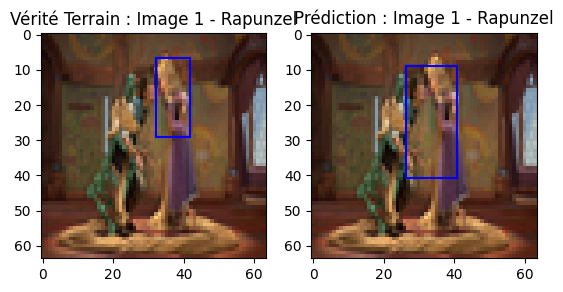

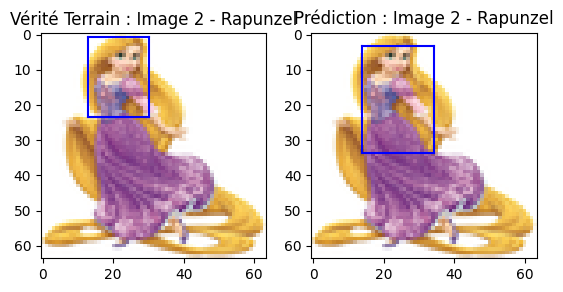

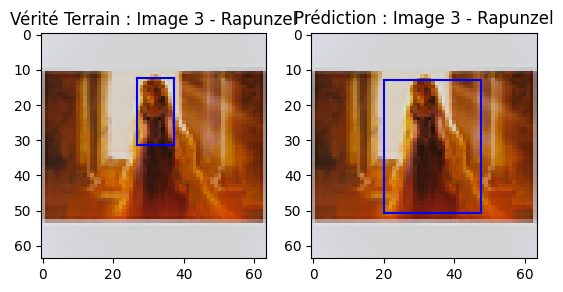

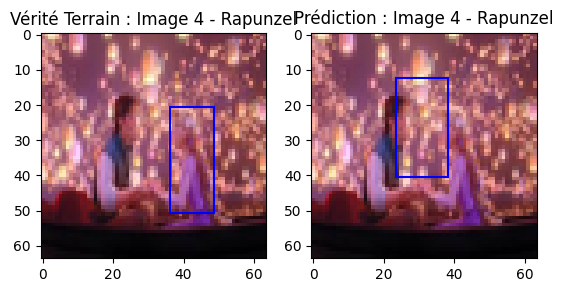

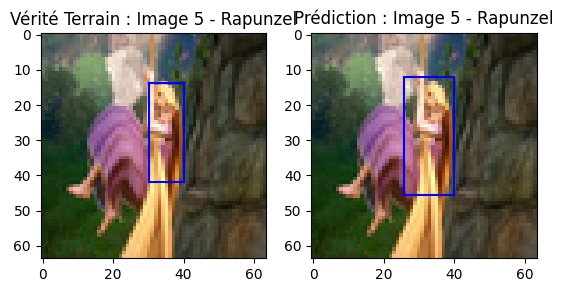

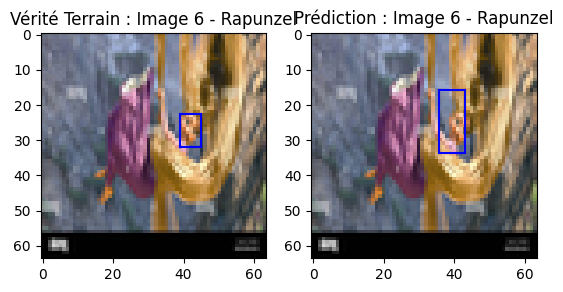

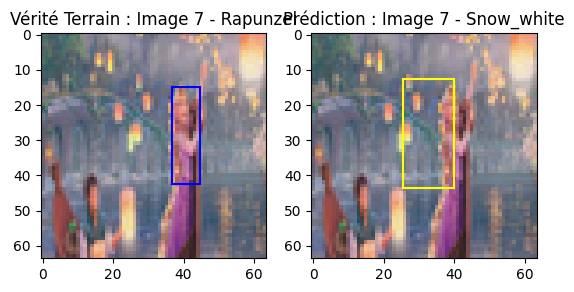

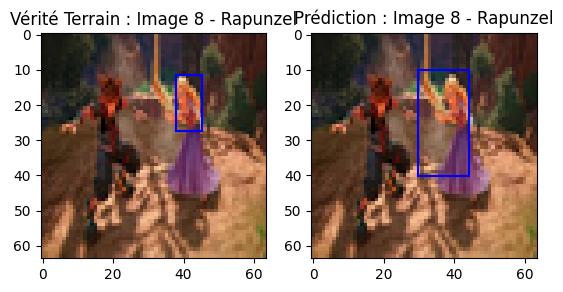

La précision globale est de 40.2%

------------------------------------------
| Classe | Précision | Rappel | F1-score |
------------------------------------------
| Rapunzel|   0.39    |  0.34  |   0.37   |
------------------------------------------
| Snow_white|   0.41    |  0.54  |   0.47   |
------------------------------------------
| Aurora |   0.40    |  0.31  |   0.35   |
------------------------------------------


In [ ]:
# Analyse des résultats : courbes d'évolution de la fonction de perte, et de l'IoU des boîtes englobantes ainsi que de la précision des classes prédites
plot_training_analysis(history, metric='loss')
plot_training_analysis(history, metric='coord_iou')
plot_training_analysis(history, metric='classes_accuracy')

# Prédiction des données de test
y_pred_presence, y_pred_coords, y_pred_classes = model.predict(x_test)
y_pred = np.zeros(y_test.shape)
for i in range(y_pred.shape[0]):
  y_pred[i, 0] = y_pred_presence[i]
  y_pred[i, 1:5] = y_pred_coords[i]
  y_pred[i, 5:] = y_pred_classes[i]

# Affichage des résultats sur plusieurs images
print_data_localisation(x_test, y_test, y_pred = y_pred, id=1, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=2, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=3, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=4, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=5, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=6, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=7, image_size=IMAGE_SIZE)
print_data_localisation(x_test, y_test, y_pred = y_pred, id=8, image_size=IMAGE_SIZE)


class_res, accuracy = global_accuracy(y_test, y_pred, iou_thres=0.4)

print(f"La précision globale est de {accuracy:.1f}%")

print()
print("------------------------------------------")
print("| Classe | Précision | Rappel | F1-score |")
print("------------------------------------------")
for i in range(NB_CLASSES):
  print(f"| {CLASS_LABELS[i]:7s}|   {class_res[i]['Precision']:.2f}    |  {class_res[i]['Rappel']:.2f}  |   {class_res[i]['F-score']:.2f}   |")
  print("------------------------------------------")


## Transfert d'apprentissage

Nous avons vu en première année comment le transfert d'apprentissage pouvait également améliorer les résultats et limiter le sur-apprentissage. L'utilisation d'un réseau pré-entraîné permet souvent de mieux généraliser.

Le bloc suivant permet de charger l'architecture du réseau VGG-16 :

In [ ]:
####################### VGG 16 fine tuning #############################################
from tensorflow.keras.applications import VGG16

conv_base = VGG16(weights='imagenet',
                  include_top=False, # On ne conserve pas la partie Dense du réseau originel
                  input_shape=(64, 64, 3))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [ ]:
IMAGE_SIZE = 64 # Dimension des images en entrée du réseau
CELL_PER_DIM = 8 # Nombre de cellules en largeur et en hauteur
BOX_PER_CELL = 1 # Nombre d'objets par cellule
NB_CLASSES = 4 # Nombre de classes du problème
PIX_PER_CELL = round(IMAGE_SIZE/CELL_PER_DIM)

CLASS_LABELS = ['snow_white', 'aurora', 'rapunzel']

In [ ]:
########################## A modif encore ###########################################################
import numpy as np

import math


import PIL
from PIL import Image
import glob, os, sys

for file in glob.glob("*.txt"):
    print(file)

def load_data_detection(ds_path):

  y_paths = []
  # Détermination du nombre d'images total
  for c in CLASS_LABELS:
    path = ds_path + c + '/'
    for file in os.listdir(path):
      if file.endswith('.txt'):
          y_paths.append(os.path.join(path, file))

  dataset_size = len(y_paths)

  # Préparation des structures de données pour x et y
  x = np.zeros((dataset_size, IMAGE_SIZE, IMAGE_SIZE, 3))
  y = []

  for i in range(len(y_paths)):
    text_path = y_paths[i]
    img_path = text_path[:-3] + 'jpg'

    if not os.path.exists(img_path):
      img_path = text_path[:-3] + 'JPG'

    # Lecture de l'image : on va remplir la variable x
    # Lecture de l'image
    img = Image.open(img_path)
    # Mise à l'échelle de l'image
    img = img.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS)
    # Remplissage de la variable x
    x[i] = np.asarray(img, dtype=np.int32)

    # Texte : coordonnées de boîtes englobantes pour remplir y
    boxes = []
    # Texte : coordonnées de boîtes englobantes pour remplir y
    text_file = open(text_path, "r")
    # Récupération des lignes du fichier texte
    rows = text_file.read().split('\n')
    # Parcours de chaque ligne
    for row in rows:
      if row != '':
        # Séparation des différentes informations
        row = list(row.split(' '))
        box = []
        # réorganisation : les 4 coordonnées de boîte englobantes (castées en flottants) d'abord
        for r in row[1:]:
          box.append(float(r))

        box_normal = [box[0]-box[2]/2, box[1]-box[3]/2, box[0]+box[2]/2, box[1]+box[3]/2]

        # Puis le label de classe (casté en entier) à la suite
        box.append(int(row[0]))
        boxes.append(box)

    y.append(boxes)
  return x, y

# Chemin vers la base de données
ds_path = "./princess_guesser/src/"
x ,y = load_data_detection(ds_path)


In [ ]:
pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 32.9 MB/s eta 0:00:00


### Utilisation d'ultralytics


In [ ]:
# !pip install ultralytics

from ultralytics import YOLO

# On charge le modèle Yolo26 hihi
model = YOLO("yolo26n.pt")

# Entrainement avec notre dataset
results = model.train(
    data="princesses.yaml",
    epochs=100,
    imgsz=64,
    project="/content/runs",
    name="princesses"
)

Ultralytics 8.4.56 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=princesses.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=64, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=princesses-2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspe


0: 64x64 1 Snow_white, 6.8ms
1: 64x64 (no detections), 6.8ms
2: 64x64 (no detections), 6.8ms
3: 64x64 1 Snow_white, 6.8ms
4: 64x64 2 Snow_whites, 6.8ms
5: 64x64 1 Snow_white, 6.8ms
6: 64x64 1 Rapunzel, 6.8ms
7: 64x64 1 Rapunzel, 6.8ms
8: 64x64 2 Auroras, 6.8ms
9: 64x64 1 Snow_white, 6.8ms
Speed: 0.1ms preprocess, 6.8ms inference, 0.3ms postprocess per image at shape (1, 3, 64, 64)
--- Résultats pour princess_guesser/src_ultralytics/test/kaggleSnow-white-disneyscreencaps-com-380.jpg ---
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([1.], device='cuda:0')
conf: tensor([0.2560], device='cuda:0')
data: tensor([[127.6328,  99.5852, 161.5456, 131.8213,   0.2560,   1.0000]], device='cuda:0')
id: None
is_track: False
orig_shape: (188, 250)
shape: torch.Size([1, 6])
xywh: tensor([[144.5892, 115.7032,  33.9128,  32.2361]], device='cuda:0')
xywhn: tensor([[0.5784, 0.6154, 0.1357, 0.1715]], device='cuda:0')
xyxy: tensor([[127.6328,  99.5852, 161.5456, 131.8213]], device='c

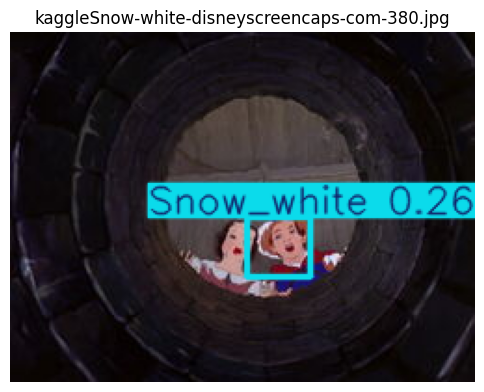

--- Résultats pour princess_guesser/src_ultralytics/test/kaggleSnow-white-disneyscreencaps-com-389.jpg ---
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([], device='cuda:0')
conf: tensor([], device='cuda:0')
data: tensor([], device='cuda:0', size=(0, 6))
id: None
is_track: False
orig_shape: (188, 250)
shape: torch.Size([0, 6])
xywh: tensor([], device='cuda:0', size=(0, 4))
xywhn: tensor([], device='cuda:0', size=(0, 4))
xyxy: tensor([], device='cuda:0', size=(0, 4))
xyxyn: tensor([], device='cuda:0', size=(0, 4))


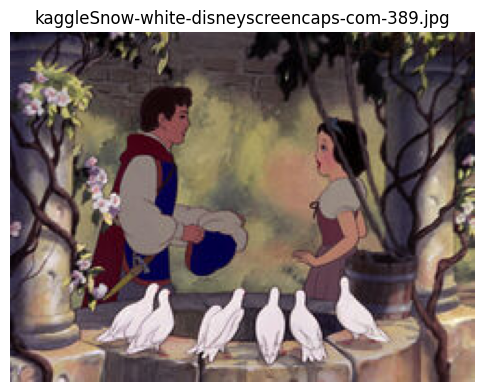

--- Résultats pour princess_guesser/src_ultralytics/test/kagglerapunzel_disney.jpg ---
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([], device='cuda:0')
conf: tensor([], device='cuda:0')
data: tensor([], device='cuda:0', size=(0, 6))
id: None
is_track: False
orig_shape: (680, 1200)
shape: torch.Size([0, 6])
xywh: tensor([], device='cuda:0', size=(0, 4))
xywhn: tensor([], device='cuda:0', size=(0, 4))
xyxy: tensor([], device='cuda:0', size=(0, 4))
xyxyn: tensor([], device='cuda:0', size=(0, 4))


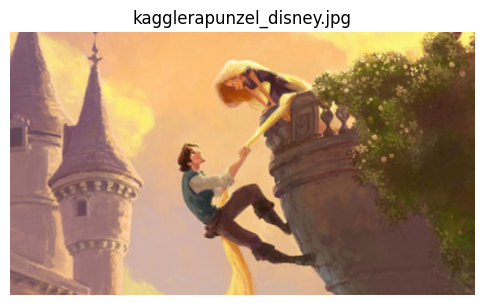

--- Résultats pour princess_guesser/src_ultralytics/test/kaggleSnow-white-disneyscreencaps-com-307.jpg ---
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([1.], device='cuda:0')
conf: tensor([0.8648], device='cuda:0')
data: tensor([[ 44.4188,   7.5390, 126.8750, 122.9908,   0.8648,   1.0000]], device='cuda:0')
id: None
is_track: False
orig_shape: (188, 250)
shape: torch.Size([1, 6])
xywh: tensor([[ 85.6469,  65.2649,  82.4562, 115.4518]], device='cuda:0')
xywhn: tensor([[0.3426, 0.3472, 0.3298, 0.6141]], device='cuda:0')
xyxy: tensor([[ 44.4188,   7.5390, 126.8750, 122.9908]], device='cuda:0')
xyxyn: tensor([[0.1777, 0.0401, 0.5075, 0.6542]], device='cuda:0')


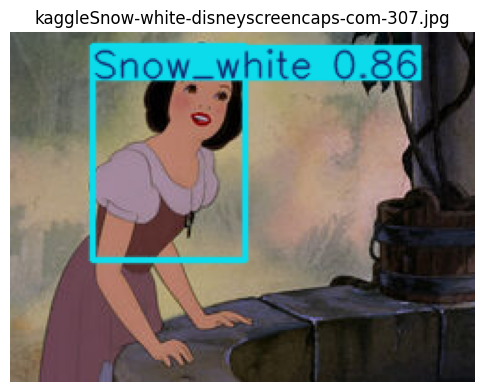

--- Résultats pour princess_guesser/src_ultralytics/test/snow_white_74.jpg ---
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([1., 1.], device='cuda:0')
conf: tensor([0.4269, 0.3330], device='cuda:0')
data: tensor([[2.6682e+02, 0.0000e+00, 7.2507e+02, 4.3900e+02, 4.2694e-01, 1.0000e+00],
        [2.6523e+02, 0.0000e+00, 8.3723e+02, 4.3900e+02, 3.3301e-01, 1.0000e+00]], device='cuda:0')
id: None
is_track: False
orig_shape: (439, 1440)
shape: torch.Size([2, 6])
xywh: tensor([[495.9432, 219.5000, 458.2458, 439.0000],
        [551.2328, 219.5000, 572.0024, 439.0000]], device='cuda:0')
xywhn: tensor([[0.3444, 0.5000, 0.3182, 1.0000],
        [0.3828, 0.5000, 0.3972, 1.0000]], device='cuda:0')
xyxy: tensor([[266.8203,   0.0000, 725.0660, 439.0000],
        [265.2316,   0.0000, 837.2341, 439.0000]], device='cuda:0')
xyxyn: tensor([[0.1853, 0.0000, 0.5035, 1.0000],
        [0.1842, 0.0000, 0.5814, 1.0000]], device='cuda:0')


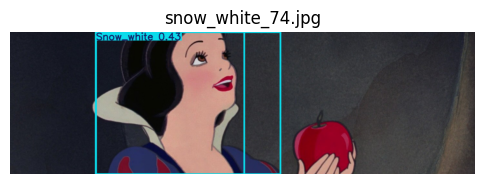

--- Résultats pour princess_guesser/src_ultralytics/test/kaggleSnow-white-disneyscreencaps-com-4518.jpg ---
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([1.], device='cuda:0')
conf: tensor([0.7968], device='cuda:0')
data: tensor([[100.6646,  16.9372, 159.5436, 113.9367,   0.7968,   1.0000]], device='cuda:0')
id: None
is_track: False
orig_shape: (188, 250)
shape: torch.Size([1, 6])
xywh: tensor([[130.1041,  65.4369,  58.8790,  96.9995]], device='cuda:0')
xywhn: tensor([[0.5204, 0.3481, 0.2355, 0.5160]], device='cuda:0')
xyxy: tensor([[100.6646,  16.9372, 159.5436, 113.9367]], device='cuda:0')
xyxyn: tensor([[0.4027, 0.0901, 0.6382, 0.6060]], device='cuda:0')


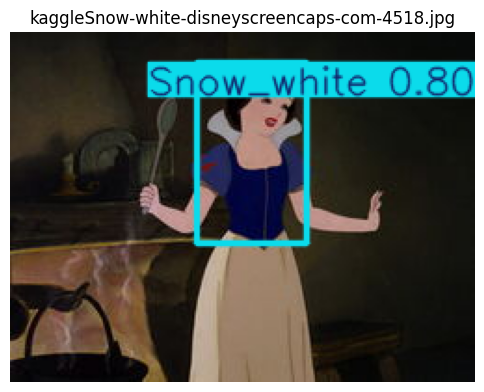

--- Résultats pour princess_guesser/src_ultralytics/test/rapunzel_53.jpg ---
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([2.], device='cuda:0')
conf: tensor([0.4590], device='cuda:0')
data: tensor([[6.1041e+02, 4.5239e+02, 7.5012e+02, 6.8648e+02, 4.5896e-01, 2.0000e+00]], device='cuda:0')
id: None
is_track: False
orig_shape: (1147, 1300)
shape: torch.Size([1, 6])
xywh: tensor([[680.2649, 569.4372, 139.7171, 234.0911]], device='cuda:0')
xywhn: tensor([[0.5233, 0.4965, 0.1075, 0.2041]], device='cuda:0')
xyxy: tensor([[610.4063, 452.3916, 750.1234, 686.4827]], device='cuda:0')
xyxyn: tensor([[0.4695, 0.3944, 0.5770, 0.5985]], device='cuda:0')


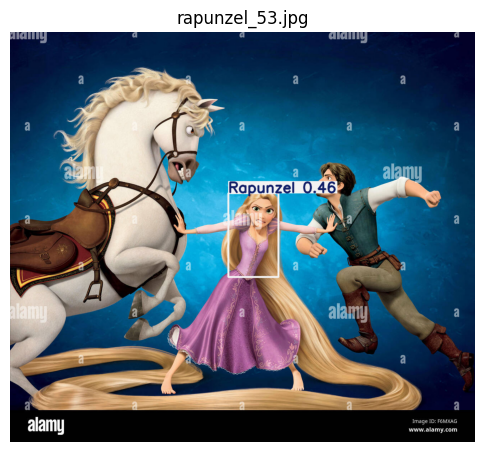

--- Résultats pour princess_guesser/src_ultralytics/test/kaggleRapunzel_brush.jpg ---
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([2.], device='cuda:0')
conf: tensor([0.3151], device='cuda:0')
data: tensor([[ 41.5418,   3.5618, 111.9375,  72.7506,   0.3151,   2.0000]], device='cuda:0')
id: None
is_track: False
orig_shape: (150, 131)
shape: torch.Size([1, 6])
xywh: tensor([[76.7397, 38.1562, 70.3958, 69.1888]], device='cuda:0')
xywhn: tensor([[0.5858, 0.2544, 0.5374, 0.4613]], device='cuda:0')
xyxy: tensor([[ 41.5418,   3.5618, 111.9375,  72.7506]], device='cuda:0')
xyxyn: tensor([[0.3171, 0.0237, 0.8545, 0.4850]], device='cuda:0')


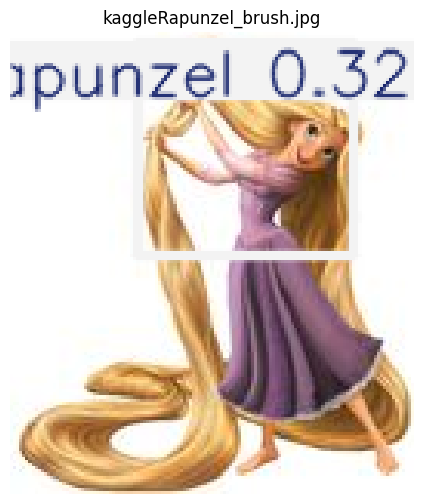

--- Résultats pour princess_guesser/src_ultralytics/test/aurora_189.jpg ---
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([0., 0.], device='cuda:0')
conf: tensor([0.4600, 0.3228], device='cuda:0')
data: tensor([[3.8136e+02, 6.2408e+01, 6.5906e+02, 4.4751e+02, 4.6000e-01, 0.0000e+00],
        [3.6316e+02, 4.9192e+01, 6.7868e+02, 5.2262e+02, 3.2278e-01, 0.0000e+00]], device='cuda:0')
id: None
is_track: False
orig_shape: (943, 1300)
shape: torch.Size([2, 6])
xywh: tensor([[520.2097, 254.9592, 277.7000, 385.1034],
        [520.9172, 285.9085, 315.5235, 473.4325]], device='cuda:0')
xywhn: tensor([[0.4002, 0.2704, 0.2136, 0.4084],
        [0.4007, 0.3032, 0.2427, 0.5020]], device='cuda:0')
xyxy: tensor([[381.3597,  62.4075, 659.0597, 447.5109],
        [363.1555,  49.1922, 678.6790, 522.6248]], device='cuda:0')
xyxyn: tensor([[0.2934, 0.0662, 0.5070, 0.4746],
        [0.2794, 0.0522, 0.5221, 0.5542]], device='cuda:0')


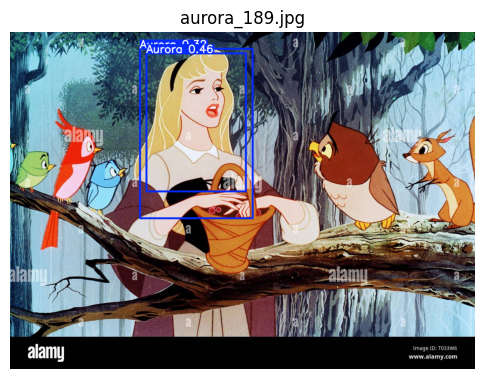

--- Résultats pour princess_guesser/src_ultralytics/test/kaggleSnow-white-disneyscreencaps-com-699.jpg ---
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([1.], device='cuda:0')
conf: tensor([0.8971], device='cuda:0')
data: tensor([[ 90.6764,  48.5705, 138.6413, 101.5994,   0.8971,   1.0000]], device='cuda:0')
id: None
is_track: False
orig_shape: (188, 250)
shape: torch.Size([1, 6])
xywh: tensor([[114.6589,  75.0849,  47.9649,  53.0289]], device='cuda:0')
xywhn: tensor([[0.4586, 0.3994, 0.1919, 0.2821]], device='cuda:0')
xyxy: tensor([[ 90.6764,  48.5705, 138.6413, 101.5994]], device='cuda:0')
xyxyn: tensor([[0.3627, 0.2584, 0.5546, 0.5404]], device='cuda:0')


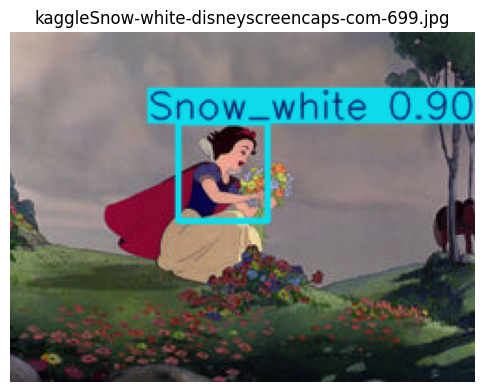

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import random
import glob

# Charge le modèle entrainé
trained_model = YOLO("runs/princesses-2/weights/best.pt")

# Récupérer toutes les images de la base de test
test_images_paths = glob.glob("princess_guesser/src_ultralytics/test/*.jpg")

# Sélectionner 10 images au pif
random_test_images = random.sample(test_images_paths, 10)

# 3. Inférence
results = trained_model.predict(source=random_test_images, imgsz=64, conf=0.25) # conf c'est le seuil de confiance

# 4. Process et visualiser les résultats
for result, img_path in zip(results, random_test_images):
    print(f"--- Résultats pour {img_path} ---")
    # Print les bounding boxes, classes, confiances
    print(result.boxes)

    # plot de l'image avec la box
    res_plotted = result.plot()

    # Display avec matplotlib
    # conversion de BGR à RGB (car cv2 charge en BGR)
    res_plotted_rgb = cv2.cvtColor(res_plotted, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 6))
    plt.imshow(res_plotted_rgb)
    plt.axis("off")
    plt.title(img_path.split('/')[-1])
    plt.show()

### Métriques pour Ultralytics

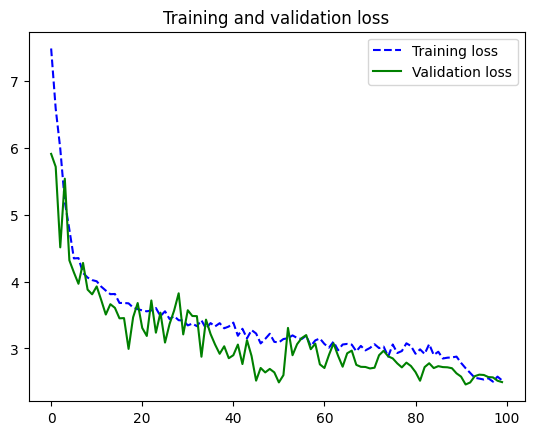

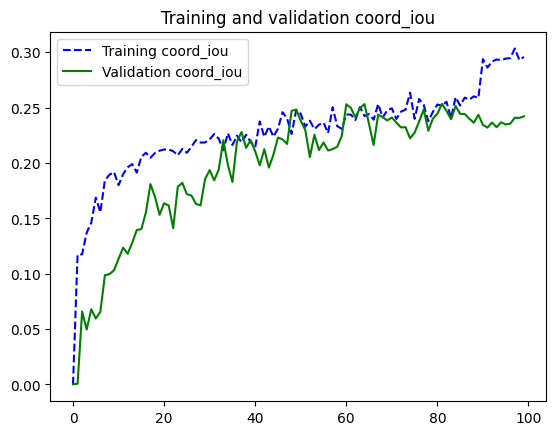

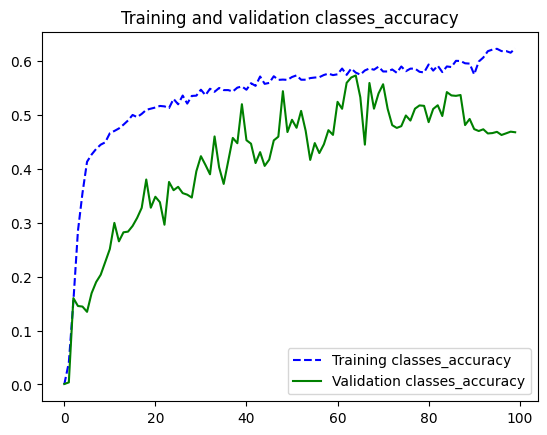

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

class YoloHistoryAdapter:
    def __init__(self, csv_filepath):
        df = pd.read_csv(csv_filepath)
        df.columns = df.columns.str.strip()

        self.history = {}

        self.history['loss'] = (df['train/box_loss'] + df['train/cls_loss'] + df['train/dfl_loss']).tolist()
        self.history['val_loss'] = (df['val/box_loss'] + df['val/cls_loss'] + df['val/dfl_loss']).tolist()

        val_acc = df['metrics/mAP50(B)'].tolist()
        val_iou = df['metrics/mAP50-95(B)'].tolist()

        self.history['val_classes_accuracy'] = val_acc
        self.history['val_coord_iou'] = val_iou

        def create_train_proxy(train_loss, val_metric):
            loss_norm = (train_loss - train_loss.min()) / (train_loss.max() - train_loss.min())
            target_max = min(1.0, max(val_metric) + 0.05)
            target_min = max(0.0, min(val_metric) - 0.2)
            return (1.0 - loss_norm) * (target_max - target_min) + target_min

        self.history['classes_accuracy'] = create_train_proxy(df['train/cls_loss'], val_acc).tolist()
        self.history['coord_iou'] = create_train_proxy(df['train/box_loss'], val_iou).tolist()


def plot_training_analysis(history, metric='loss'):

  loss = history.history[metric]
  val_loss = history.history['val_' + metric]

  epochs = range(len(loss))

  plt.plot(epochs, loss, 'b', linestyle="--",label='Training ' + metric)
  plt.plot(epochs, val_loss, 'g', label='Validation ' + metric)
  plt.title('Training and validation ' + metric)
  plt.legend()

  plt.show()


csv_path = "runs/princesses-2/results.csv"

if os.path.exists(csv_path):
    yolo_history = YoloHistoryAdapter(csv_path)

    plot_training_analysis(yolo_history, metric='loss')
    plot_training_analysis(yolo_history, metric='coord_iou')
    plot_training_analysis(yolo_history, metric='classes_accuracy')
else:
    print(f"File not found: {csv_path}. Please check your YOLO runs directory!")

In [ ]:
from ultralytics import YOLO

# Charge le modèle entrainé
trained_model = YOLO("runs/princesses-2/weights/best.pt")

# évaluation sur le dataset
metrics = trained_model.val(data="princess_guesser/princesses.yaml", split="test")

# 2. Extraire P, R calculés par YOLO et recréer la liste "class_res"
class_res = [{'Precision': 0.0, 'Rappel': 0.0, 'F-score': 0.0} for _ in range(3)]

for idx, class_id in enumerate(metrics.box.ap_class_index):
    p = metrics.box.p[idx]  # Précision
    r = metrics.box.r[idx]  # Rappel
    f1 = (2 * p * r) / (p + r) if (p + r) > 0 else 0.0 # F1-score

    class_res[class_id]['Precision'] = p
    class_res[class_id]['Rappel'] = r
    class_res[class_id]['F-score'] = f1

# YOLO n'a pas exactement la même définition "d'Accuracy globale",
# on utilise donc le mAP50 (%) comme proxy de la précision de détection globale.
accuracy = metrics.box.map50 * 100

CLASS_LABELS = ['Aurora', 'Snow_white', 'Rapunzel']
NB_CLASSES = len(CLASS_LABELS)


print(f"La précision globale est de {accuracy:.1f}%")

print()
print("------------------------------------------")
print("| Classe | Précision | Rappel | F1-score |")
print("------------------------------------------")
for i in range(NB_CLASSES):
  print(f"| {CLASS_LABELS[i]:7s}|   {class_res[i]['Precision']:.2f}    |  {class_res[i]['Rappel']:.2f}  |   {class_res[i]['F-score']:.2f}   |")
  print("------------------------------------------")

Ultralytics 8.4.56 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,375,421 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1660.1±958.4 MB/s, size: 138.6 KB)
val: Scanning /content/princess_guesser/src_ultralytics/test... 98 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 98/98 1.0Kit/s 0.1s
val: New cache created: /content/princess_guesser/src_ultralytics/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.3it/s 3.1s
                   all         98        100      0.736      0.648      0.724      0.437
                Aurora         32         32      0.759      0.688      0.782      0.484
            Snow_white         35         35      0.736      0.657        0.7      0.499
              Rapunzel         33         33      0.712      0.599      0.691      0.328
Speed: 0.7ms preprocess, 15.2ms inference, 0.0ms los

x : tenseur
y : boxes

In [ ]:
IMAGE_SIZE = 64 # Dimension des images en entrée du réseau
CELL_PER_DIM = 8 # Nombre de cellules en largeur et en hauteur
BOX_PER_CELL = 1 # Nombre d'objets par cellule
NB_CLASSES = 3 # Nombre de classes du problème
PIX_PER_CELL = round(IMAGE_SIZE/CELL_PER_DIM)

CLASS_LABELS = ['Snow_white', 'Aurora', 'Rapunzel']


In [ ]:
import numpy as np
import imghdr
import math
import PIL
from PIL import Image
import glob, os, sys
# glob : Return a possibly empty list of path names that match pathname

for file in glob.glob("*.txt"):
    print(file)

def load_data_detection(ds_path):

  y_paths = []
  # Détermination du nombre d'images total
  for c in CLASS_LABELS:
    path = ds_path + c + '/'
    for file in os.listdir(path):
      if file.endswith('.txt'):
          y_paths.append(os.path.join(path, file))

  dataset_size = len(y_paths)

  # Préparation des structures de données pour x et y
  x = np.zeros((dataset_size, IMAGE_SIZE, IMAGE_SIZE, 3))
  y = []

  for i in range(len(y_paths)): # ACHANGER !!!!!!!!!!!!!!!!!!!!!!
    text_path = y_paths[i]
    img_path = text_path[:-3] + 'jpg'

    if not os.path.exists(img_path):
      img_path = text_path[:-3] + 'JPG'

    # Lecture de l'image : on va remplir la variable x
    # Lecture de l'image
    img = Image.open(img_path)
    # Mise à l'échelle de l'image
    img = img.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS)
    # Remplissage de la variable x
    x[i] = np.asarray(img, dtype=np.int32)

    # Texte : coordonnées de boîtes englobantes pour remplir y
    boxes = []
    # Texte : coordonnées de boîtes englobantes pour remplir y
    text_file = open(text_path, "r")
    # Récupération des lignes du fichier texte
    rows = text_file.read().split('\n')
    # Parcours de chaque ligne
    for row in rows:
      if row != '':
        # Séparation des différentes informations
        row = list(row.split(' '))
        box = []
        # réorganisation : les 4 coordonnées de boîte englobantes (castées en flottants) d'abord
        for r in row[1:]:
          box.append(float(r))

        box_normal = [box[0]-box[2]/2, box[1]-box[3]/2, box[0]+box[2]/2, box[1]+box[3]/2]

        # Puis le label de classe (casté en entier) à la suite
        box.append(int(row[0]))
        boxes.append(box)

    y.append(boxes)
  return x, y

# Chemin vers la base de données
ds_path = "princess_guesser/src/"
x ,y = load_data_detection(ds_path)

In [ ]:
from scipy.special import softmax
import matplotlib.pyplot as plt

def print_data_detection(x, y, id=None, classes=CLASS_LABELS, image_size=IMAGE_SIZE):
  if id==None:
    # Tirage aléatoire d'une image dans la base
    num_img = np.random.randint(x.shape[0])
  else:
    num_img = id

  img = x[num_img]
  if np.max(img) > 1:
    img = img/255
  boxes = y[num_img]

  colors = ["blue", "white", "pink"] # Différentes couleurs pour les différentes classes

  # Affichage de l'image
  plt.imshow(img)
  for box in boxes:

    # Détermination de la classe
    class_id = box[4]

    # Détermination des extrema de la boîte englobante
    p_x = [(box[0]-box[2]/2) * IMAGE_SIZE, (box[0]+box[2]/2) * IMAGE_SIZE]
    p_y = [(box[1]-box[3]/2) * IMAGE_SIZE, (box[1]+box[3]/2) * IMAGE_SIZE]

    # Affichage de la boîte englobante, dans la bonne couleur
    plt.plot([p_x[0], p_x[0]],p_y,color=colors[class_id])
    plt.plot([p_x[1], p_x[1]],p_y,color=colors[class_id])
    plt.plot(p_x,[p_y[0],p_y[0]],color=colors[class_id])
    plt.plot(p_x,[p_y[1],p_y[1]],color=colors[class_id], label=classes[class_id])
    #plt.title("Vérité Terrain : Image {}".format(num_img, classes[class_id]))

  plt.legend(bbox_to_anchor=(1.04,1), loc="upper left")
  plt.axis('off')
  plt.show()


print_data_detection(x, y, id=22)